# LipoQ
### Black-box variational quantum search for lipid nanoparticle compositions
**IBM Quantum Qiskit Fall Fest — single-file submission notebook**

This `.ipynb` contains the project source, configuration, compact real experiment evidence, and executed tables and figures. **This is the only file to submit.** No LipoQ repository, ZIP, YAML, or result file needs to accompany it.

**To read:** open the saved notebook; no downloads or execution are needed. **To execute:** select a Python 3.12 kernel and Run All. Setup cells restore the embedded implementation and evidence, install tested dependencies when necessary, and download the pinned official COMET assets. The checkpoint is approximately **586 MiB**, downloaded separately at runtime; it is not included in the submission file. Initial execution therefore requires internet access and Git. The first download can take several minutes.

**Reading guide:** Sections 1–6 explain the formulation space and algorithm; Sections 7–8 execute a three-update demo and implementation checks; Sections 9–11 analyze completed experiments. The full multi-seed study is never launched automatically. Large setup cells are collapsed for readability and can be expanded to inspect the source.

**Evidence boundary:** planned seeds are 21, 22, and 23. Only completed archives are counted; unavailable seeds are listed explicitly. Scores are frozen COMET predictions, not measured biological efficacy.

## 1. Project overview

We search for lipid nanoparticle (LNP) formulations with high predicted delivery performance under a fixed cell and manufacturing condition. A shallow parameterized quantum circuit samples bitstrings, a deterministic decoder maps them to four lipid identities and molar fractions, and the original pretrained COMET model evaluates each new formulation. First-order SPSA updates the circuit angles to increase the **shot-weighted mean predicted score**. The best formulation encountered is retained separately from the mean learning objective.

```text
Circuit parameters → measured bitstrings → lipid identities + fractions
        ↑                                           ↓
    SPSA update ← negative mean score ← frozen COMET prediction
```

COMET weights remain frozen. The objective is evaluated directly: no quadratic surrogate, QUBO, or QAOA is used. Quantum circuits run on a local statevector simulator with finite-shot measurements.

## 2. Problem and composition space

Each formulation contains one **ionizable lipid**, one **phospholipid**, one **sterol**, and one **PEG lipid**. Candidates are the 14 molecular entries in the pinned COMET library, grouped as follows. Names are library labels; IDs and molecular representations define the actual inputs.

| Group | COMET molecule IDs | Number of choices | Configured fraction bounds | Step |
|---|---|---:|---:|---:|
| Ionizable lipid | 0, 4, 5, 6, 7, 8, 9 | 7 | 0.30–0.55 | 0.05 |
| Phospholipid | 1, 13 | 2 | 0.10–0.25 | 0.05 |
| Sterol | 2, 10, 12 | 3 | 0.15–0.59 | 0.01 |
| PEG lipid | 3, 11 | 2 | 0.01–0.03 | 0.01 |

The four fractions must sum to exactly 1. This leaves **72 feasible fraction tuples**, with a feasible sterol minimum of 0.17. Together with **7 × 2 × 3 × 2 = 84** lipid combinations, the search contains **6,048 distinct compositions**.

The prediction target is **DC2.4** (`in_house_lnp_DC24_luc`). N/P is fixed at **5.287338420806728** and aqueous:organic mixing ratio at **1:1**, following an existing upstream reference formulation. These are fixed process inputs, distinct from the four lipid molar fractions. The candidate library and supported cell come from COMET; the grid and optimizer settings are our experimental design. Marginal data coverage does not guarantee joint-domain validity for every combination.

## 3. Environment, configuration, and embedded evidence

The next three setup cells make this notebook self-contained with respect to **our implementation and experiment records**. They install tested packages if needed, write the embedded Python modules and configuration into `lipoq_workspace`, and verify the embedded evidence by SHA256. This generated directory is created automatically; it is not a submission dependency.

The pretrained COMET checkpoint and upstream source are external scientific assets. Section 4 obtains them from their official distribution and verifies the pinned revision and checksum. No score substitution is used if setup or inference fails.

The defaults work from any writable directory. Optional environment variables `LIPOQ_WORKSPACE`, `LIPOQ_COMET_REPO`, and `LIPOQ_COMET_CHECKPOINT` allow a different generated directory or reuse of already-downloaded official assets. A compatible environment and verified cached assets allow offline reruns. The live demo and archived results remain separate.

In [1]:
# Install only missing or different tested versions in this Python kernel.
import importlib.metadata
import importlib.util
import os
from pathlib import Path
import shutil
import subprocess
import sys

if not (3, 11) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("Use a Python 3.12 kernel (Python 3.11 is also supported).")
REQUIRED_VERSIONS = {'numpy': '1.26.4',
 'scipy': '1.15.3',
 'torch': '2.6.0',
 'qiskit': '2.4.2',
 'qiskit-algorithms': '0.4.0',
 'PyYAML': '6.0.3',
 'lmdb': '3.0.0',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'tensorboardX': '2.6.5',
 'tqdm': '4.70.1',
 'rdkit': '2026.9.1',
 'tokenizers': '0.23.3',
 'matplotlib': '3.11.2',
 'gdown': '6.5.1',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'pylatexenc': '2.11'}
needed = []
for package, version in REQUIRED_VERSIONS.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        needed.append(f"{package}=={version}")
if needed:
    # Avoid silently retaining already-imported versions after an upgrade.
    loaded = set(sys.modules) & {"numpy", "torch", "scipy", "pandas", "qiskit", "rdkit"}
    if importlib.util.find_spec("pip"):
        command = [sys.executable, "-m", "pip", "install", "--quiet", *needed]
    elif shutil.which("uv"):
        command = ["uv", "pip", "install", "--python", sys.executable, *needed]
    else:
        raise RuntimeError("Install pip or uv in this kernel, then run this cell again.")
    subprocess.run(command, check=True)
    if loaded:
        raise RuntimeError("Dependencies installed. Restart the kernel and Run All.")
print("Tested package versions are installed. No LipoQ repository checkout is required.")
if not shutil.which("git"):
    raise RuntimeError("Install Git before downloading the pinned upstream COMET source.")


Tested package versions are installed. No LipoQ repository checkout is required.


In [2]:
# Embedded readable project source. Expand this cell to inspect all modules.
# Materialize the exact source bytes so model provenance hashes stay valid.
import hashlib
import json

EMBEDDED_SOURCES = {'configs/vqa.yaml': '# LNP composition search. Paths are relative to this file.\n'
                     '# Override seed with --seed; outputs are grouped under seed-<seed>.\n'
                     '# Persistent cache saves inference time; wall times are cache-dependent.\n'
                     'seed: 21\n'
                     'comet:\n'
                     '  repo: ../vendor/COMET\n'
                     '  checkpoint: ../artifacts/comet_lipid_fold0.pt\n'
                     '  preprocessing_seed: 0\n'
                     '  batch_size: 16\n'
                     '  cpu_threads: 4\n'
                     'condition:\n'
                     '  cell: DC2.4\n'
                     '  np_ratio: 5.287338420806728\n'
                     "  volumetric_ratio: '1:1'\n"
                     'search:\n'
                     '  candidates:\n'
                     '    ionizable:\n'
                     '    - 0\n'
                     '    - 4\n'
                     '    - 5\n'
                     '    - 6\n'
                     '    - 7\n'
                     '    - 8\n'
                     '    - 9\n'
                     '    phospholipid:\n'
                     '    - 1\n'
                     '    - 13\n'
                     '    sterol:\n'
                     '    - 2\n'
                     '    - 10\n'
                     '    - 12\n'
                     '    peg:\n'
                     '    - 3\n'
                     '    - 11\n'
                     '  ratios:\n'
                     '    denominator: 1000\n'
                     '    bounds:\n'
                     '      ionizable:\n'
                     '        min: 0.3\n'
                     '        max: 0.55\n'
                     '        step: 0.05\n'
                     '      phospholipid:\n'
                     '        min: 0.1\n'
                     '        max: 0.25\n'
                     '        step: 0.05\n'
                     '      sterol:\n'
                     '        min: 0.15\n'
                     '        max: 0.59\n'
                     '        step: 0.01\n'
                     '      peg:\n'
                     '        min: 0.01\n'
                     '        max: 0.03\n'
                     '        step: 0.01\n'
                     'circuit:\n'
                     '  qubits: auto\n'
                     '  depth: 1\n'
                     '  shots: 128\n'
                     'optimizer:\n'
                     '  iterations: 200\n'
                     '  learning_rate: 2.0\n'
                     '  perturbation: 0.15\n'
                     '  alpha: 0.602\n'
                     '  gamma: 0.101\n'
                     '  stability_constant: 10\n'
                     '  resamplings: 2\n'
                     '  paired_sampling: true\n'
                     '  trust_region: true\n'
                     '  last_avg: 5\n'
                     '  initialization: uniform\n'
                     '  early_stopping:\n'
                     '    enabled: true\n'
                     '    min_iterations: 20\n'
                     '    patience: 3\n'
                     '    window: 5\n'
                     '    min_delta: 0.02\n'
                     '    confidence_z: 1.0\n'
                     'output:\n'
                     '  directory: ../results/lnp_search\n'
                     '  cache: ../artifacts/comet_scores.sqlite\n',
 'notebooks/data/manifest.json': '{\n'
                                 '  "schema_version": 1,\n'
                                 '  "prepared_at": "2026-11-07T01:24:16.949419+08:00",\n'
                                 '  "file": "experiment_snapshot.json.gz",\n'
                                 '  "sha256": '
                                 '"e20be4128b2161e0b004a79709eec9ef534a2b5f03c65564feb6202d16149ab4",\n'
                                 '  "availability": [\n'
                                 '    {\n'
                                 '      "seed": 21,\n'
                                 '      "vqa": "completed",\n'
                                 '      "random": "completed"\n'
                                 '    },\n'
                                 '    {\n'
                                 '      "seed": 22,\n'
                                 '      "vqa": "not available",\n'
                                 '      "random": "not available"\n'
                                 '    },\n'
                                 '    {\n'
                                 '      "seed": 23,\n'
                                 '      "vqa": "not available",\n'
                                 '      "random": "not available"\n'
                                 '    }\n'
                                 '  ],\n'
                                 '  "description": "Verified real-COMET archives; compact score/count '
                                 'records, not synthetic data. Original file hashes are inside the '
                                 'snapshot."\n'
                                 '}\n',
 'scripts/setup_comet.py': '"""Download pinned original COMET assets; preserve an existing checkout."""\n'
                           'import argparse\n'
                           'import json\n'
                           'from pathlib import Path\n'
                           'import subprocess\n'
                           'import sys\n'
                           '\n'
                           'ROOT = Path(__file__).resolve().parents[1]\n'
                           'sys.path.insert(0, str(ROOT / "src"))\n'
                           'from common.comet import CHECKPOINT_ID, CHECKPOINT_SHA256, COMET_COMMIT, sha256\n'
                           '\n'
                           '\n'
                           'def main():\n'
                           '    parser = argparse.ArgumentParser(description=__doc__)\n'
                           '    parser.add_argument("--repo", type=Path, default=ROOT / "vendor/COMET")\n'
                           '    parser.add_argument("--checkpoint", type=Path, default=ROOT / '
                           '"artifacts/comet_lipid_fold0.pt")\n'
                           '    args = parser.parse_args()\n'
                           '    repo, checkpoint = args.repo.resolve(), args.checkpoint.resolve()\n'
                           '    if not repo.exists():\n'
                           '        repo.parent.mkdir(parents=True, exist_ok=True)\n'
                           '        subprocess.run(["git", "clone", '
                           '"https://github.com/alvinchangw/COMET.git", str(repo)], check=True)\n'
                           '        subprocess.run(["git", "-C", str(repo), "checkout", "--detach", '
                           'COMET_COMMIT], check=True)\n'
                           '    actual = subprocess.check_output(["git", "-C", str(repo), "rev-parse", '
                           '"HEAD"], text=True).strip()\n'
                           '    if actual != COMET_COMMIT:\n'
                           '        raise RuntimeError(f"Existing checkout is {actual}; choose another '
                           '--repo path for pinned {COMET_COMMIT}")\n'
                           '    checkpoint.parent.mkdir(parents=True, exist_ok=True)\n'
                           '    if not checkpoint.exists():\n'
                           '        import gdown\n'
                           '        partial = checkpoint.with_suffix(".download")\n'
                           '        gdown.download(id=CHECKPOINT_ID, output=str(partial), quiet=False, '
                           'use_cookies=False)\n'
                           '        if sha256(partial) != CHECKPOINT_SHA256:\n'
                           '            raise RuntimeError(f"Downloaded checkpoint checksum mismatch: '
                           '{partial}")\n'
                           '        partial.replace(checkpoint)\n'
                           '    if sha256(checkpoint) != CHECKPOINT_SHA256:\n'
                           '        raise RuntimeError("Existing checkpoint checksum mismatch; no files were '
                           'overwritten")\n'
                           '    report = {"comet_commit": actual, "checkpoint_sha256": CHECKPOINT_SHA256,\n'
                           '              "checkpoint_id": CHECKPOINT_ID, "checkpoint_bytes": '
                           'checkpoint.stat().st_size,\n'
                           '              "repo": str(repo), "checkpoint": str(checkpoint)}\n'
                           '    (checkpoint.parent / "assets.json").write_text(json.dumps(report, indent=2) '
                           '+ "\\n")\n'
                           '    print(json.dumps(report, indent=2))\n'
                           '\n'
                           '\n'
                           'if __name__ == "__main__":\n'
                           '    main()\n'
                           '\n',
 'src/common/__init__.py': '"""Shared COMET inference, composition space, evaluation, and output '
                           'utilities."""\n',
 'src/common/cache.py': '"""SQLite score cache namespaced by exact model, input data and cell '
                        'conditions."""\n'
                        'import math\n'
                        'from pathlib import Path\n'
                        'import sqlite3\n'
                        '\n'
                        '\n'
                        'class ScoreCache:\n'
                        '    def __init__(self, path, namespace):\n'
                        '        Path(path).parent.mkdir(parents=True, exist_ok=True)\n'
                        '        self.db = sqlite3.connect(path)\n'
                        '        self.db.execute("CREATE TABLE IF NOT EXISTS scores (namespace TEXT, '
                        'composition TEXT, score REAL NOT NULL, PRIMARY KEY(namespace, composition))")\n'
                        '        self.namespace = namespace\n'
                        '\n'
                        '    def get(self, key):\n'
                        '        row = self.db.execute("SELECT score FROM scores WHERE namespace=? AND '
                        'composition=?", (self.namespace, key)).fetchone()\n'
                        '        if row is not None and not math.isfinite(row[0]):\n'
                        '            raise ValueError("Nonfinite cached score")\n'
                        '        return None if row is None else row[0]\n'
                        '\n'
                        '    def put_many(self, values):\n'
                        '        if any(not math.isfinite(score) for _, score in values):\n'
                        '            raise ValueError("Refusing to cache a nonfinite score")\n'
                        '        with self.db:\n'
                        '            self.db.executemany("INSERT OR REPLACE INTO scores VALUES (?, ?, ?)",\n'
                        '                                [(self.namespace, key, score) for key, score in '
                        'values])\n'
                        '\n'
                        '    def close(self):\n'
                        '        self.db.close()\n',
 'src/common/comet.py': '"""Frozen original COMET model, original conformers and original preprocessing.\n'
                        '\n'
                        'No surrogate, retraining, score rescaling or synthetic fallback is provided.\n'
                        'The sole supported checkpoint is the upstream lipid-only fold-0 deployment model.\n'
                        '"""\n'
                        'from contextlib import redirect_stdout\n'
                        'from copy import deepcopy\n'
                        'import hashlib\n'
                        'import importlib.metadata\n'
                        'import io\n'
                        'import json\n'
                        'from pathlib import Path\n'
                        'import pickle\n'
                        'import subprocess\n'
                        'import sys\n'
                        'import time\n'
                        '\n'
                        'from .encoding import COMET_TYPES, GROUPS, Composition\n'
                        '\n'
                        'COMET_COMMIT = "eee99d2055bad3b7d253c436b3eb7603550b37c5"\n'
                        'CHECKPOINT_ID = "1C1j2od4wwUISn9GJegHATe4cLtY2NwEU"\n'
                        'CHECKPOINT_SHA256 = '
                        '"8de532194feead3662a33d62855801ebe55b02014eb05e3eedbeb27ee60f7335"\n'
                        'SCHEMA = "task_schemas/in_house_lnp_master_schema_NPratio_AOvolratio.json"\n'
                        'CELLS = {"DC2.4": "in_house_lnp_DC24_luc", "B16-F10": "in_house_lnp_B16F10_luc"}\n'
                        'NAMES = {0: "ALC-0315", 1: "DOPE", 2: "Cholesterol", 3: "C14-PEG (COMET '
                        'representation)",\n'
                        '         6: "SM-102", 10: "beta-Sitosterol", 11: "C18-PEG (COMET representation)", '
                        '13: "DSPC"}\n'
                        'SCORE_DESCRIPTION = "Frozen COMET contrastive delivery ranking score; higher is '
                        'better; not measured efficacy or a probability"\n'
                        '\n'
                        '\n'
                        'def sha256(path):\n'
                        '    with Path(path).open("rb") as stream:\n'
                        '        return hashlib.file_digest(stream, "sha256").hexdigest()\n'
                        '\n'
                        '\n'
                        'def digest_json(value):\n'
                        '    return hashlib.sha256(json.dumps(value, sort_keys=True, '
                        'allow_nan=False).encode()).hexdigest()\n'
                        '\n'
                        '\n'
                        'def read_catalog(library):\n'
                        '    import lmdb\n'
                        '    records = json.loads((library / "in_house_lnp/infer.json").read_text())\n'
                        '    types = {}\n'
                        '    for row in records:\n'
                        '        for c in row["components"]:\n'
                        '            types.setdefault(c["smi"], set()).add(c["component_type"])\n'
                        '    env = lmdb.open(str(library / "mol.lmdb"), subdir=False, readonly=True, '
                        'lock=False)\n'
                        '    catalog = {}\n'
                        '    try:\n'
                        '        with env.begin() as txn:\n'
                        '            for key, value in txn.cursor():\n'
                        '                # Trusted, pinned upstream dataset, containing RDKit conformers.\n'
                        '                mol = pickle.loads(value)\n'
                        '                mid = int(key)\n'
                        '                if len(types[mol["smi"]]) != 1:\n'
                        '                    raise ValueError(f"Ambiguous component type for mol_id {mid}")\n'
                        '                ctype = next(iter(types[mol["smi"]]))\n'
                        '                catalog[mid] = {"name": NAMES.get(mid, f"COMET-{ctype}-{mid}"), '
                        '"mol_id": mid,\n'
                        '                                "component_type": ctype, "smiles": mol["smi"],\n'
                        '                                "conformer_count": len(mol["coordinates"])}\n'
                        '    finally:\n'
                        '        env.close()\n'
                        '    return catalog, records\n'
                        '\n'
                        '\n'
                        'class CometOracle:\n'
                        '    def __init__(self, config, condition, log_path):\n'
                        '        start = time.perf_counter()\n'
                        '        self.config, self.condition = config, condition\n'
                        '        if condition["cell"] not in CELLS:\n'
                        '            raise ValueError(f"Unsupported cell {condition[\'cell\']!r}. This '
                        'checkpoint supports {list(CELLS)}")\n'
                        '        self.target = CELLS[condition["cell"]]\n'
                        '        repo, checkpoint = Path(config["repo"]), Path(config["checkpoint"])\n'
                        '        if not (repo / "unimol/models/unimol.py").exists() or not '
                        'checkpoint.is_file():\n'
                        '            raise FileNotFoundError("COMET source/checkpoint missing. Run: python '
                        'scripts/setup_comet.py")\n'
                        '        self.checkpoint_hash = sha256(checkpoint)\n'
                        '        if self.checkpoint_hash != CHECKPOINT_SHA256:\n'
                        '            raise ValueError("Checkpoint checksum mismatch; refusing '
                        'unknown/corrupt pretrained weights")\n'
                        '        revision = subprocess.check_output(["git", "-C", str(repo), "rev-parse", '
                        '"HEAD"], text=True).strip()\n'
                        '        if revision != COMET_COMMIT:\n'
                        '            raise ValueError(f"COMET revision must be {COMET_COMMIT}; run '
                        'setup_comet.py")\n'
                        '        if subprocess.check_output(["git", "-C", str(repo), "status", '
                        '"--porcelain", "--untracked-files=no"], text=True).strip():\n'
                        '            raise ValueError("Pinned COMET checkout has modified files; use an '
                        'unmodified checkout")\n'
                        '        self.library = next((repo / '
                        '"experiments/in_house_lnp_library").glob("*lmdb"))\n'
                        '        self.catalog, self.records = read_catalog(self.library)\n'
                        '        sys.path.insert(0, str(repo))\n'
                        '        log = io.StringIO()\n'
                        '        try:\n'
                        '            with redirect_stdout(log):\n'
                        '                import torch\n'
                        '                from unimol.core import tasks\n'
                        '                from unimol.core.data import Dictionary\n'
                        '                self.torch = torch\n'
                        '                torch.set_num_threads(config["cpu_threads"])\n'
                        '                # weights_only=False is needed for the legacy Namespace '
                        'checkpoint.\n'
                        '                # Its publisher-sourced SHA256 is verified BEFORE deserialization.\n'
                        '                state = torch.load(checkpoint, map_location="cpu", '
                        'weights_only=False)\n'
                        '                args = deepcopy(state["args"])\n'
                        '                args.data = str(repo / "experiments")\n'
                        '                args.task_name = str(self.library)\n'
                        '                args.full_dataset_task_schema_path = SCHEMA\n'
                        '                # Field added upstream after this lipid-only checkpoint was '
                        'trained.\n'
                        '                args.include_excipients = False\n'
                        '                args.load_full_np_model = True\n'
                        '                args.cpu, args.fp16, args.bf16 = True, False, False\n'
                        '                args.mode, args.seed, args.num_workers = "infer", '
                        'config["preprocessing_seed"], 0\n'
                        '                args.noise_augment_percent = False\n'
                        '                self.task = tasks.setup_task(args)\n'
                        '                self.model = self.task.build_model(args)\n'
                        '                self.model.load_state_dict(state["model"], strict=True)\n'
                        '                del state\n'
                        '                self.model.float().eval().requires_grad_(False)\n'
                        '                self.task.load_concat_dataset("infer")\n'
                        '                self.dataset = self.task.dataset("infer")\n'
                        '                self.dataset.set_epoch(1)\n'
                        '                # Upstream NP dataset does not propagate epoch to its molecule '
                        'dataset.\n'
                        '                # Set it explicitly: otherwise hash((seed, None, id)) varies by '
                        'process.\n'
                        '                self.dataset.mol_dataset.set_epoch(1)\n'
                        '                self.template = self.dataset[0]\n'
                        '                self.component_dictionary = '
                        'self.task.component_type_dictionary["component_type"]["dictionary"]\n'
                        '                self.volume_dictionary = '
                        'Dictionary.load_from_list(self.task.np_prop_schema["volumetric_ratio"]["dictionary"])\n'
                        '        finally:\n'
                        '            Path(log_path).write_text(log.getvalue())\n'
                        '        if condition["volumetric_ratio"] not in ("1:1", "3:1"):\n'
                        '            raise ValueError("volumetric_ratio must be \'1:1\' or \'3:1\' for this '
                        'experiment")\n'
                        '        np_values = [r["NP_ratio"] for r in self.records]\n'
                        '        if not min(np_values) <= condition["np_ratio"] <= max(np_values):\n'
                        '            raise ValueError("N/P ratio lies outside the observed lipid-only data '
                        'envelope")\n'
                        '        self.provenance = {\n'
                        '            "source": "real_pretrained_COMET", "score_description": '
                        'SCORE_DESCRIPTION,\n'
                        '            "comet_commit": revision, "checkpoint_sha256": self.checkpoint_hash,\n'
                        '            "checkpoint_url": '
                        'f"https://drive.google.com/file/d/{CHECKPOINT_ID}/view",\n'
                        '            "strict_state_dict": True, "frozen": True, "device": "cpu", "dtype": '
                        '"float32",\n'
                        '            "condition": condition, "preprocessing_seed": args.seed, '
                        '"preprocessing_epoch": 1,\n'
                        '            "conformers": "one deterministic upstream conformer per molecule; no '
                        'TTA averaging",\n'
                        '            "mol_lmdb_sha256": sha256(self.library / "mol.lmdb"),\n'
                        '            "schema_sha256": sha256(repo / "experiments" / SCHEMA),\n'
                        '            "atom_dictionary_sha256": sha256(repo / "experiments/dict.txt"),\n'
                        '            "adapter_sha256": sha256(__file__),\n'
                        '            "versions": {p: importlib.metadata.version(p) for p in ("torch", '
                        '"numpy", "scipy", "rdkit")},\n'
                        '        }\n'
                        '        self.fingerprint = digest_json(self.provenance)\n'
                        '        self.load_seconds = time.perf_counter() - start\n'
                        '        self.evaluation_seconds = 0.0\n'
                        '        self.forward_seconds = 0.0\n'
                        '        self.compositions_evaluated = 0\n'
                        '        self.forward_batches = 0\n'
                        '\n'
                        '    def validate_search(self, encoder):\n'
                        '        bounds = {}\n'
                        '        four = [r for r in self.records if len(r["components"]) == 4 and\n'
                        '                {c["component_type"] for c in r["components"]} == '
                        'set(COMET_TYPES)]\n'
                        '        for i, (group, ctype, ids) in enumerate(zip(GROUPS, COMET_TYPES, '
                        'encoder.candidates)):\n'
                        '            for mid in ids:\n'
                        '                if mid not in self.catalog or self.catalog[mid]["component_type"] '
                        '!= ctype:\n'
                        '                    raise ValueError(f"mol_id {mid} does not belong to {group} in '
                        'COMET")\n'
                        '            values = [c["percent"] for r in four for c in r["components"] if '
                        'c["component_type"] == ctype]\n'
                        '            low, high = min(values), max(values)\n'
                        '            chosen = [r[i] / encoder.denominator for r in encoder.ratios]\n'
                        '            if min(chosen) < low - 1e-9 or max(chosen) > high + 1e-9:\n'
                        '                raise ValueError(f"{group}: search range outside observed data '
                        'envelope [{low}, {high}]")\n'
                        '            bounds[group] = {"observed_min": low, "observed_max": high,\n'
                        '                             "search_min": min(chosen), "search_max": max(chosen)}\n'
                        '        return {"source_records": len(self.records), "four_component_records": '
                        'len(four),\n'
                        '                "marginal_fraction_bounds": bounds,\n'
                        '                "note": "Marginal bounds and known molecules do not establish joint '
                        'in-domain validity or experimental efficacy."}\n'
                        '\n'
                        '    def _sample(self, composition):\n'
                        '        t = self.torch\n'
                        '        sample = deepcopy(self.template)\n'
                        '        components = [{"mol_id": mid, "smi": self.catalog[mid]["smiles"], '
                        '"component_type": ctype,\n'
                        '                       "mol": fraction, "percent": fraction}\n'
                        '                      for mid, fraction, ctype in zip(composition.lipid_ids, '
                        'composition.fractions, COMET_TYPES)]\n'
                        '        sample["net_input.mol_ids"] = t.tensor(composition.lipid_ids, '
                        'dtype=t.long)\n'
                        '        # Match upstream float64 fraction collation; GaussianLayer casts to '
                        'float32.\n'
                        '        sample["net_input.percents"] = t.tensor(composition.fractions, '
                        'dtype=t.float64)\n'
                        '        sample["net_input.component_types"] = '
                        't.tensor([self.component_dictionary.index(c) for c in COMET_TYPES])\n'
                        '        sample["net_input.components"] = components\n'
                        '        sample["net_input.lnp_ids"] = composition.key\n'
                        '        sample["net_input.NP_ratio"] = self.condition["np_ratio"]\n'
                        '        sample["net_input.volumetric_ratio"] = '
                        'self.volume_dictionary.index(self.condition["volumetric_ratio"])\n'
                        '        sample["net_input.NP_ratio_mask"] = True\n'
                        '        sample["net_input.volumetric_ratio_mask"] = True\n'
                        '        # Labels are NOT passed into model.forward or used by the search '
                        'objective.\n'
                        '        return sample\n'
                        '\n'
                        '    def _forward(self, batch):\n'
                        '        batch.pop("target", None)\n'
                        '        start = time.perf_counter()\n'
                        '        with self.torch.inference_mode():\n'
                        '            scores = self.model(batch, '
                        'np_classification_head_name=self.task.args.classification_head_name)[0][self.target]\n'
                        '        self.forward_seconds += time.perf_counter() - start\n'
                        '        self.forward_batches += 1\n'
                        '        if not self.torch.isfinite(scores).all():\n'
                        '            raise RuntimeError("COMET returned nonfinite scores; stopping without '
                        'substituting scores")\n'
                        '        return scores.flatten().tolist()\n'
                        '\n'
                        '    def predict(self, compositions):\n'
                        '        scores = []\n'
                        '        start = time.perf_counter()\n'
                        '        try:\n'
                        '            for offset in range(0, len(compositions), self.config["batch_size"]):\n'
                        '                chunk = compositions[offset:offset+self.config["batch_size"]]\n'
                        '                batch = self.dataset.collater([self._sample(c) for c in chunk])\n'
                        '                scores.extend(self._forward(batch))\n'
                        '                self.compositions_evaluated += len(chunk)\n'
                        '        finally:\n'
                        '            self.evaluation_seconds += time.perf_counter() - start\n'
                        '        return scores\n'
                        '\n'
                        '    def preflight(self):\n'
                        '        """Compare the adapter with upstream collation on a real known '
                        'formulation."""\n'
                        '        start = time.perf_counter()\n'
                        '        previous_evaluation_seconds = self.evaluation_seconds\n'
                        '        original = self.dataset.collater([self.dataset[0]])\n'
                        '        net = original["net_input"]\n'
                        '        ids = tuple(c["mol_id"] for c in net["components"][0])\n'
                        '        # Upstream record 0 is exactly 0.355 / 0.163 / 0.472 / 0.01.\n'
                        '        fractions = tuple(c["percent"] for c in net["components"][0])\n'
                        '        comp = Composition(ids, tuple(round(x * 1000) for x in fractions), 1000)\n'
                        '        # Compare at the configured process conditions for both paths.\n'
                        '        original["net_input"]["NP_ratio"][:] = self.condition["np_ratio"]\n'
                        '        original["net_input"]["volumetric_ratio"][:] = '
                        'self.volume_dictionary.index(self.condition["volumetric_ratio"])\n'
                        '        upstream_score = self._forward(original)[0]\n'
                        '        adapter_score, repeat_score = self.predict([comp, comp])\n'
                        '        self.evaluation_seconds = previous_evaluation_seconds + '
                        'time.perf_counter()-start\n'
                        '        self.compositions_evaluated += 1\n'
                        '        error = abs(adapter_score-upstream_score)\n'
                        '        if error > 1e-5 or abs(repeat_score-adapter_score) > 1e-6:\n'
                        '            raise RuntimeError(f"COMET preflight parity/repeatability failed '
                        '(error={error})")\n'
                        '        return {"status": "ok", "source": "real_pretrained_COMET", "cell": '
                        'self.condition["cell"],\n'
                        '                "upstream_score": upstream_score, "adapter_score": adapter_score,\n'
                        '                "absolute_error": error, "repeat_score": repeat_score,\n'
                        '                "seconds": time.perf_counter()-start, "composition": '
                        'comp.as_dict(self.catalog)}\n'
                        '\n',
 'src/common/config.py': '"""Validation and path resolution for settings shared by both search methods."""\n'
                         'from pathlib import Path\n'
                         'import math\n'
                         'import yaml\n'
                         '\n'
                         'from .encoding import GROUPS\n'
                         '\n'
                         '\n'
                         'def keys(mapping, expected, label):\n'
                         '    if not isinstance(mapping, dict) or set(mapping) != set(expected):\n'
                         '        raise ValueError(f"{label} requires exactly these keys: {\', '
                         '\'.join(expected)}")\n'
                         '\n'
                         '\n'
                         'def integer(value, label, low=1, high=1_000_000):\n'
                         '    if type(value) is not int or not low <= value <= high:\n'
                         '        raise ValueError(f"{label} must be an integer in [{low}, {high}]")\n'
                         '\n'
                         '\n'
                         'def positive(value, label):\n'
                         '    if type(value) not in (int, float) or not math.isfinite(value) or value <= 0:\n'
                         '        raise ValueError(f"{label} must be finite and positive")\n'
                         '\n'
                         '\n'
                         'def load_common_config(path):\n'
                         '    """Read YAML or an archived JSON config; resolve paths relative to that '
                         'file."""\n'
                         '    path = Path(path).resolve()\n'
                         '    cfg = yaml.safe_load(path.read_text())\n'
                         '    if not isinstance(cfg, dict):\n'
                         "        raise ValueError('Configuration must be a mapping')\n"
                         "    required = {'seed', 'comet', 'condition', 'search', 'output'}\n"
                         '    if not required <= cfg.keys():\n'
                         "        raise ValueError(f'Missing shared settings: "
                         "{sorted(required-cfg.keys())}')\n"
                         "    keys(cfg['comet'], ('repo', 'checkpoint', 'preprocessing_seed', 'batch_size', "
                         "'cpu_threads'), 'comet')\n"
                         "    keys(cfg['condition'], ('cell', 'np_ratio', 'volumetric_ratio'), 'condition')\n"
                         "    keys(cfg['search'], ('candidates', 'ratios'), 'search')\n"
                         "    keys(cfg['search']['candidates'], GROUPS, 'search.candidates')\n"
                         "    keys(cfg['search']['ratios'], ('denominator', 'bounds'), 'ratios')\n"
                         "    keys(cfg['search']['ratios']['bounds'], GROUPS, 'ratios.bounds')\n"
                         '    for group in GROUPS:\n'
                         "        keys(cfg['search']['ratios']['bounds'][group], ('min', 'max', 'step'), "
                         'group)\n'
                         "    keys(cfg['output'], ('directory', 'cache'), 'output')\n"
                         "    integer(cfg['seed'], 'seed', 0, 2**32-1)\n"
                         "    integer(cfg['comet']['preprocessing_seed'], 'preprocessing_seed', 0, 2**32-1)\n"
                         "    integer(cfg['comet']['batch_size'], 'batch_size', 1, 128)\n"
                         "    integer(cfg['comet']['cpu_threads'], 'cpu_threads', 1, 16)\n"
                         "    positive(cfg['condition']['np_ratio'], 'np_ratio')\n"
                         "    for section, name in (('comet', 'repo'), ('comet', 'checkpoint'), ('output', "
                         "'directory'), ('output', 'cache')):\n"
                         '        cfg[section][name] = str((path.parent / '
                         'Path(cfg[section][name]).expanduser()).resolve())\n'
                         '    return cfg\n',
 'src/common/encoding.py': '"""Total bitstring decoder over four lipid identities and a bounded simplex '
                           'grid."""\n'
                           'from dataclasses import dataclass\n'
                           'from decimal import Decimal\n'
                           'from itertools import product\n'
                           'from math import prod\n'
                           '\n'
                           'GROUPS = ("ionizable", "phospholipid", "sterol", "peg")\n'
                           '# Preserve the original COMET type identifiers; HL maps to phospholipid here.\n'
                           'COMET_TYPES = ("IL", "HL", "CH", "PEG")\n'
                           '\n'
                           '\n'
                           '@dataclass(frozen=True)\n'
                           'class Composition:\n'
                           '    lipid_ids: tuple[int, int, int, int]\n'
                           '    ticks: tuple[int, int, int, int]\n'
                           '    denominator: int\n'
                           '\n'
                           '    def __post_init__(self):\n'
                           '        if (len(self.lipid_ids) != 4 or len(self.ticks) != 4 or\n'
                           '            type(self.denominator) is not int or self.denominator <= 0 or\n'
                           '            any(type(v) is not int or v < 0 for v in self.lipid_ids) or\n'
                           '            any(type(v) is not int or v <= 0 for v in self.ticks) or\n'
                           '            sum(self.ticks) != self.denominator):\n'
                           '            raise ValueError("Composition must contain four lipid IDs and '
                           'positive fractions summing exactly to 1")\n'
                           '\n'
                           '    @property\n'
                           '    def fractions(self):\n'
                           '        return tuple(v / self.denominator for v in self.ticks)\n'
                           '\n'
                           '    @property\n'
                           '    def key(self):\n'
                           '        # Fractions, rather than bitstrings, eliminate alias evaluations.\n'
                           '        fractions = [str(Decimal(v) / self.denominator) for v in self.ticks]\n'
                           '        return ",".join(map(str, self.lipid_ids)) + "|" + ",".join(fractions)\n'
                           '\n'
                           '    def as_dict(self, catalog):\n'
                           '        return {\n'
                           '            "components": [\n'
                           '                {"group": group, "mol_id": mid, "name": catalog[mid]["name"],\n'
                           '                 "smiles": catalog[mid]["smiles"], "molar_fraction": fraction}\n'
                           '                for group, mid, fraction in zip(GROUPS, self.lipid_ids, '
                           'self.fractions)\n'
                           '            ],\n'
                           '            "fraction_ticks": list(self.ticks), "denominator": '
                           'self.denominator,\n'
                           '            "fraction_sum": sum(self.ticks) / self.denominator,\n'
                           '        }\n'
                           '\n'
                           '\n'
                           'class CompositionEncoder:\n'
                           '    def __init__(self, config):\n'
                           '        self.candidates = tuple(tuple(config["candidates"][g]) for g in GROUPS)\n'
                           '        for group, ids in zip(GROUPS, self.candidates):\n'
                           '            if not ids or len(set(ids)) != len(ids) or any(type(i) is not int or '
                           'i < 0 for i in ids):\n'
                           '                raise ValueError(f"{group}: require nonempty, unique nonnegative '
                           'integer mol_ids")\n'
                           '        self.denominator = config["ratios"]["denominator"]\n'
                           '        if type(self.denominator) is not int or self.denominator <= 0:\n'
                           '            raise ValueError("ratios.denominator must be a positive integer")\n'
                           '        axes = []\n'
                           '        for group in GROUPS:\n'
                           '            spec = config["ratios"]["bounds"][group]\n'
                           '            vals = []\n'
                           '            for key in ("min", "max", "step"):\n'
                           '                scaled = Decimal(str(spec[key])) * self.denominator\n'
                           '                if not scaled.is_finite() or scaled != '
                           'scaled.to_integral_value():\n'
                           '                    raise ValueError(f"{group}.{key} must lie on the denominator '
                           'grid")\n'
                           '                vals.append(int(scaled))\n'
                           '            low, high, step = vals\n'
                           '            if not 0 < low <= high <= self.denominator or step <= 0 or '
                           '(high-low) % step:\n'
                           '                raise ValueError(f"{group}: invalid bounds or step (all '
                           'components must be present)")\n'
                           '            axes.append(range(low, high + 1, step))\n'
                           '        # Enumerate three axes; determine the fourth exactly in integer '
                           'arithmetic.\n'
                           '        if prod(len(axis) for axis in axes[:3]) > 2_000_000:\n'
                           '            raise ValueError("Ratio grid too large; increase steps (max 2 '
                           'million grid checks)")\n'
                           '        self.ratios = tuple((a, b, c, self.denominator-a-b-c)\n'
                           '                            for a, b, c in product(*axes[:3])\n'
                           '                            if self.denominator-a-b-c in axes[3])\n'
                           '        if not self.ratios:\n'
                           '            raise ValueError("No feasible molar fractions sum to 1 within the '
                           'configured grid")\n'
                           '        sizes = tuple(len(ids) for ids in self.candidates) + '
                           '(len(self.ratios),)\n'
                           '        self.widths = tuple((size - 1).bit_length() for size in sizes)\n'
                           '        self.num_qubits = sum(self.widths)\n'
                           '        if not 1 <= self.num_qubits <= 20:\n'
                           '            raise ValueError("Search requires 1–20 qubits; adjust candidates or '
                           'ratio resolution")\n'
                           '        self.cardinality = prod(sizes)\n'
                           '\n'
                           '    def decode(self, bitstring):\n'
                           '        # Qiskit prints q[n-1] ... q[0]; low bits select the ionizable lipid.\n'
                           '        if len(bitstring) != self.num_qubits or set(bitstring) - {"0", "1"}:\n'
                           '            raise ValueError(f"Expected exactly {self.num_qubits} binary '
                           'digits")\n'
                           '        remaining = int(bitstring, 2)\n'
                           '        indices = []\n'
                           '        for width in self.widths:\n'
                           '            indices.append(remaining & ((1 << width) - 1))\n'
                           '            remaining >>= width\n'
                           '        ids = tuple(options[i % len(options)] for options, i in '
                           'zip(self.candidates, indices))\n'
                           '        return Composition(ids, self.ratios[indices[-1] % len(self.ratios)], '
                           'self.denominator)\n'
                           '\n'
                           '    def composition_at(self, index):\n'
                           '        """Index unique formulations uniformly, independently of bitstring '
                           'aliases."""\n'
                           '        if not 0 <= index < self.cardinality:\n'
                           '            raise IndexError(index)\n'
                           '        index, ratio_index = divmod(int(index), len(self.ratios))\n'
                           '        ids = []\n'
                           '        for options in reversed(self.candidates):\n'
                           '            index, lipid_index = divmod(index, len(options))\n'
                           '            ids.append(options[lipid_index])\n'
                           '        return Composition(tuple(reversed(ids)), self.ratios[ratio_index], '
                           'self.denominator)\n'
                           '\n'
                           '    def compositions(self):\n'
                           '        return (self.composition_at(i) for i in range(self.cardinality))\n'
                           '\n'
                           '    def metadata(self):\n'
                           '        return {"num_qubits": self.num_qubits, "field_widths_lsb_first": '
                           'dict(zip((*GROUPS, "ratio"), self.widths)),\n'
                           '                "feasible_ratio_count": len(self.ratios), '
                           '"unique_search_space_size": self.cardinality,\n'
                           '                "ratio_ticks": self.ratios, "denominator": self.denominator,\n'
                           '                "unused_codes": "modulo each field; non-power-of-two fields have '
                           'alias bias"}\n'
                           '\n',
 'src/common/evaluation.py': '"""Direct COMET evaluation, composition caching, and shot-weighted '
                             'objectives."""\n'
                             'import json\n'
                             'import math\n'
                             'from pathlib import Path\n'
                             'import time\n'
                             '\n'
                             '\n'
                             'class Evaluator:\n'
                             '    def __init__(self, oracle, cache, catalog, candidates_path):\n'
                             '        self.oracle, self.cache, self.catalog = oracle, cache, catalog\n'
                             '        self.candidates_path = Path(candidates_path)\n'
                             '        self.best = None\n'
                             '        self.seen = set()\n'
                             '        self.sampled_shots = 0\n'
                             '        self.composition_requests = 0\n'
                             '        self.unique_comet_evaluations = 0\n'
                             '        self.persistent_cache_hits = 0\n'
                             '        self.started = time.perf_counter()\n'
                             '\n'
                             '    def score(self, compositions):\n'
                             '        """Evaluate unique inputs in first-encounter order; cache every valid '
                             'score."""\n'
                             '        compositions = list(compositions)\n'
                             '        if not compositions:\n'
                             "            raise ValueError('An evaluation batch must not be empty')\n"
                             '        self.composition_requests += len(compositions)\n'
                             '        unique = {c.key: c for c in compositions}\n'
                             '        scores, pending = {}, []\n'
                             '        for key, composition in unique.items():\n'
                             '            value = self.cache.get(key)\n'
                             '            if value is None:\n'
                             '                pending.append(composition)\n'
                             '            else:\n'
                             '                scores[key] = value\n'
                             '                if key not in self.seen:\n'
                             '                    self.persistent_cache_hits += 1\n'
                             '        if pending:\n'
                             '            predicted = self.oracle.predict(pending)\n'
                             '            if len(predicted) != len(pending):\n'
                             "                raise RuntimeError('COMET prediction count mismatch')\n"
                             '            values = [(c.key, float(score)) for c, score in zip(pending, '
                             'predicted)]\n'
                             '            self.cache.put_many(values)  # Rejects nonfinite scores before '
                             'recording.\n'
                             '            scores.update(values)\n'
                             '            self.unique_comet_evaluations += len(values)\n'
                             '        pending_keys = {c.key for c in pending}\n'
                             "        with self.candidates_path.open('a') as stream:\n"
                             '            for key, composition in unique.items():\n'
                             "                entry = {'composition_key': key, 'comet_score': scores[key],\n"
                             '                         **composition.as_dict(self.catalog)}\n'
                             "                if self.best is None or entry['comet_score'] > "
                             "self.best['comet_score']:\n"
                             '                    self.best = entry\n'
                             '                if key not in self.seen:\n'
                             '                    self.seen.add(key)\n'
                             "                    stream.write(json.dumps({**entry, 'from_persistent_cache': "
                             'key not in pending_keys,\n'
                             "                        'unique_evaluations': len(self.seen), "
                             "'best_so_far_score': self.best['comet_score'],\n"
                             "                        'elapsed_seconds': time.perf_counter()-self.started}, "
                             "allow_nan=False)+'\\n')\n"
                             '        return [scores[c.key] for c in compositions]\n'
                             '\n'
                             '    def evaluate_counts(self, counts, encoder):\n'
                             '        if not counts or any(type(n) is not int or n <= 0 for n in '
                             'counts.values()):\n'
                             "            raise ValueError('Counts must contain positive integer "
                             "frequencies')\n"
                             '        compositions, frequencies = {}, {}\n'
                             '        for bits, count in sorted(counts.items()):\n'
                             '            composition = encoder.decode(bits)\n'
                             '            compositions[composition.key] = composition\n'
                             '            frequencies[composition.key] = frequencies.get(composition.key, '
                             '0)+count\n'
                             '        previous_evaluations = self.unique_comet_evaluations\n'
                             '        predicted = self.score(compositions.values())\n'
                             '        scores = dict(zip(compositions, predicted))\n'
                             '        shots = sum(frequencies.values())\n'
                             '        self.sampled_shots += shots\n'
                             '        mean = sum(frequencies[key]*scores[key] for key in frequencies)/shots\n'
                             '        variance = sum(frequencies[key]*(scores[key]-mean)**2 for key in '
                             'frequencies)/shots\n'
                             "        return {'mean_comet_score': mean,\n"
                             "                'shot_standard_error': math.sqrt(variance/(shots-1)) if shots "
                             '> 1 else None,\n'
                             "                'batch_best_score': max(scores.values()), 'best_so_far_score': "
                             "self.best['comet_score'],\n"
                             "                'unique_in_batch': len(compositions),\n"
                             "                'new_comet_evaluations': "
                             'self.unique_comet_evaluations-previous_evaluations,\n'
                             "                'sampled_shots': shots, 'total_unique_sampled': "
                             'len(self.seen)}\n'
                             '\n'
                             '    def stats(self):\n'
                             "        result = {'unique_sampled_compositions': len(self.seen),\n"
                             "                  'unique_comet_evaluations': self.unique_comet_evaluations,\n"
                             "                  'unique_loaded_from_persistent_cache': "
                             'self.persistent_cache_hits,\n'
                             "                  'composition_requests': self.composition_requests}\n"
                             '        if self.sampled_shots:\n'
                             "            result.update({'sampled_shots': self.sampled_shots,\n"
                             "                           'duplicate_shots': "
                             'self.sampled_shots-len(self.seen),\n'
                             "                           'avoided_comet_evaluations': "
                             'self.sampled_shots-self.unique_comet_evaluations})\n'
                             '        return result\n',
 'src/common/plotting.py': '"""Shared noninteractive figure export and isolated plotting failure '
                           'handling."""\n'
                           'import os\n'
                           'from pathlib import Path\n'
                           'import sys\n'
                           'import tempfile\n'
                           'import time\n'
                           '\n'
                           'from .results import write_json\n'
                           '\n'
                           "COLORS = ('#2367BD', '#DE7B24', '#159782', '#9467BD', '#C44768', '#677C8A')\n"
                           '\n'
                           '\n'
                           'def prepare_matplotlib():\n'
                           '    # Reuse the per-user temporary font cache instead of scanning fonts per '
                           'run.\n'
                           "    os.environ.setdefault('MPLCONFIGDIR', "
                           "str(Path(tempfile.gettempdir())/'lipoq-matplotlib'))\n"
                           '    import matplotlib\n'
                           "    matplotlib.use('Agg')\n"
                           '    import matplotlib.pyplot as plt\n'
                           "    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,\n"
                           "                         'axes.labelcolor': '#273B50', 'text.color': '#172B40',\n"
                           "                         'xtick.color': '#536679', 'ytick.color': '#536679',\n"
                           "                         'axes.spines.top': False, 'axes.spines.right': False,\n"
                           "                         'axes.edgecolor': '#C7D1DC', 'axes.titleweight': "
                           "'bold',\n"
                           "                         'svg.fonttype': 'path', 'savefig.facecolor': 'white'})\n"
                           '    return matplotlib, plt\n'
                           '\n'
                           '\n'
                           'def save_figure(fig, output, name):\n'
                           '    output = Path(output)\n'
                           '    output.mkdir(parents=True, exist_ok=True)\n'
                           "    for extension in ('png', 'svg'):\n"
                           "        target = output/f'{name}.{extension}'\n"
                           "        temp = output/f'.{name}.tmp.{extension}'\n"
                           '        fig.savefig(temp, dpi=200, format=extension)\n'
                           '        temp.replace(target)\n'
                           '\n'
                           '\n'
                           'def export_automatically(directory, generate):\n'
                           '    """A plot failure must not discard a successfully completed experiment."""\n'
                           '    started = time.perf_counter()\n'
                           '    try:\n'
                           "        status = {'status': 'completed', **generate()}\n"
                           '    except Exception as error:\n'
                           "        status = {'status': 'failed', 'error_type': type(error).__name__, "
                           "'error': str(error)}\n"
                           "        print(f'Experiment saved; automatic plot failed: {error}', "
                           'file=sys.stderr, flush=True)\n'
                           "    status['seconds'] = time.perf_counter()-started\n"
                           "    write_json(Path(directory)/'plot_status.json', status)\n"
                           '    return status\n'
                           '\n'
                           '\n',
 'src/common/results.py': '"""Incremental, machine-readable outputs; never overwrite another experiment."""\n'
                          'from datetime import datetime\n'
                          'import csv\n'
                          'import json\n'
                          'import os\n'
                          'from pathlib import Path\n'
                          'import secrets\n'
                          'from zoneinfo import ZoneInfo\n'
                          '\n'
                          '\n'
                          'def write_json(path, value):\n'
                          '    path = Path(path)\n'
                          '    temp = path.with_suffix(path.suffix + ".tmp")\n'
                          '    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False, '
                          'allow_nan=False) + "\\n")\n'
                          '    os.replace(temp, path)\n'
                          '\n'
                          '\n'
                          'def create_run_dir(root, prefix):\n'
                          '    stamp = datetime.now(ZoneInfo("Asia/Hong_Kong")).strftime("%Y%m%d-%H%M%S")\n'
                          '    path = Path(root) / f"{prefix}-{stamp}-{secrets.token_hex(3)}"\n'
                          '    path.mkdir(parents=True, exist_ok=False)\n'
                          '    return path\n'
                          '\n'
                          '\n'
                          'def append_jsonl(path, row):\n'
                          '    with Path(path).open("a") as stream:\n'
                          '        stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '
                          '"\\n")\n'
                          '\n'
                          '\n'
                          'def append_csv(path, row):\n'
                          '    path = Path(path)\n'
                          '    new = not path.exists()\n'
                          '    with path.open("a", newline="") as stream:\n'
                          '        writer = csv.DictWriter(stream, fieldnames=list(row))\n'
                          '        if new:\n'
                          '            writer.writeheader()\n'
                          '        writer.writerow(row)\n'
                          '\n',
 'src/random_search/__init__.py': '"""Uniform random composition search, separate from the VQA '
                                  'optimizer."""\n',
 'src/random_search/__main__.py': 'from .cli import main\n\nraise SystemExit(main())\n',
 'src/random_search/cli.py': '"""Run random search alone, matching a completed VQA archive."""\n'
                             'import argparse\n'
                             'from datetime import datetime\n'
                             'import importlib.metadata\n'
                             'import json\n'
                             'from pathlib import Path\n'
                             'import platform\n'
                             'import sys\n'
                             'import time\n'
                             'import traceback\n'
                             '\n'
                             'from common.cache import ScoreCache\n'
                             'from common.evaluation import Evaluator\n'
                             'from common.comet import CometOracle, SCORE_DESCRIPTION\n'
                             'from common.config import integer\n'
                             'from common.plotting import export_automatically\n'
                             'from common.results import append_csv, create_run_dir, write_json\n'
                             'from .comparison import plot_comparison, write_comparison\n'
                             'from .reference import load_reference\n'
                             'from .search import random_search\n'
                             '\n'
                             '\n'
                             'def run_random(source, output=None, seed=None, dry_run=False):\n'
                             '    started = time.perf_counter()\n'
                             '    directory = oracle = evaluator = cache = None\n'
                             '    try:\n'
                             '        reference = load_reference(source)\n'
                             "        cfg, encoder, budget = reference['config'], reference['encoder'], "
                             "reference['budget']\n"
                             "        seed = cfg['seed'] if seed is None else seed\n"
                             "        integer(seed, 'random seed', 0, 2**32-1)\n"
                             '        output = Path(output).resolve() if output else '
                             "reference['path'].parent/'random-search'\n"
                             "        plan = {'reference_run': str(reference['path']), 'seed': seed, 'cell': "
                             "cfg['condition']['cell'],\n"
                             "                'search_space_size': encoder.cardinality, 'unique_budget': "
                             'budget,\n'
                             "                'batch_size': cfg['comet']['batch_size'], 'output_root': "
                             'str(output),\n'
                             "                'cache': 'fresh in-memory cache; no persistent VQA score "
                             "reuse',\n"
                             "                'automatic_plot': 'plots/comparison.png and "
                             "plots/comparison.svg'}\n"
                             '        if dry_run:\n'
                             "            print(json.dumps({'status': 'dry_run', **plan}, indent=2))\n"
                             '            return 0\n'
                             "        directory = create_run_dir(output, 'random')\n"
                             "        print(json.dumps({'status': 'starting', 'results': str(directory), "
                             '**plan}, indent=2), flush=True)\n'
                             "        write_json(directory/'config.json', {**plan, 'method': 'random', "
                             "'comet': cfg['comet'],\n"
                             "                                             'condition': cfg['condition'], "
                             "'search': cfg['search']})\n"
                             "        write_json(directory/'reference.json', {'path': "
                             "str(reference['path']), 'sha256': reference['hashes']})\n"
                             "        write_json(directory/'encoding.json', encoder.metadata())\n"
                             "        write_json(directory/'environment.json', {\n"
                             "            'started_at': datetime.now().astimezone().isoformat(), 'python': "
                             'sys.version,\n'
                             "            'platform': platform.platform(),\n"
                             "            'packages': {d.metadata['Name']: d.version for d in "
                             'importlib.metadata.distributions()}})\n'
                             "        print('Loading verified pretrained COMET on CPU ...', flush=True)\n"
                             "        oracle = CometOracle(cfg['comet'], cfg['condition'], "
                             "directory/'comet_load.log')\n"
                             "        if oracle.fingerprint != reference['summary']['model_fingerprint']:\n"
                             "            raise ValueError('COMET fingerprint differs from the VQA archive; "
                             "refusing an incompatible comparison.')\n"
                             "        write_json(directory/'model.json', oracle.provenance)\n"
                             "        write_json(directory/'catalog.json', oracle.catalog)\n"
                             "        write_json(directory/'domain.json', oracle.validate_search(encoder))\n"
                             '        preflight = oracle.preflight()\n'
                             "        write_json(directory/'preflight.json', preflight)\n"
                             '        preflight_seconds = oracle.evaluation_seconds\n'
                             '        preflight_evaluations = oracle.compositions_evaluated\n'
                             "        print('Real COMET preflight passed. Starting uniform random search.', "
                             'flush=True)\n'
                             "        cache = ScoreCache(':memory:', oracle.fingerprint)\n"
                             '        evaluator = Evaluator(oracle, cache, oracle.catalog, '
                             "directory/'candidates.jsonl')\n"
                             '        search_started = time.perf_counter()\n'
                             '        next_progress = 0\n'
                             '\n'
                             '        def on_batch(done, state):\n'
                             '            nonlocal next_progress\n'
                             "            append_csv(directory/'progress.csv', {\n"
                             "                'unique_compositions': done, 'best_so_far_score': "
                             "state.best['comet_score'],\n"
                             "                'elapsed_search_seconds': time.perf_counter()-search_started,\n"
                             "                'comet_seconds': "
                             'oracle.evaluation_seconds-preflight_seconds})\n'
                             "            write_json(directory/'best.json', state.best)\n"
                             '            if done >= next_progress or done == budget:\n'
                             "                print(f'Random seed={seed}: {done}/{budget} compositions, "
                             'best={state.best["comet_score"]:.6f}\', flush=True)\n'
                             "                next_progress = done+max(cfg['comet']['batch_size'], "
                             'budget//10)\n'
                             '\n'
                             '        search = random_search(encoder, evaluator, budget, seed, '
                             "cfg['comet']['batch_size'], on_batch)\n"
                             '        search_seconds = time.perf_counter()-search_started\n'
                             '        if len(evaluator.seen) != budget:\n'
                             "            raise RuntimeError('Random search did not complete the matched "
                             "unique budget.')\n"
                             '        counts = evaluator.stats()\n'
                             "        summary = {'status': 'completed', 'command': 'random', 'seed': seed,\n"
                             "                   'score_description': SCORE_DESCRIPTION, "
                             "'model_fingerprint': oracle.fingerprint,\n"
                             "                   'reference_run': str(reference['path']), 'search': search, "
                             "'best': evaluator.best,\n"
                             "                   'counts': counts, 'search_seconds': search_seconds,\n"
                             "                   'preflight_composition_evaluations': "
                             'preflight_evaluations,\n'
                             "                   'timing': {'model_load_seconds': oracle.load_seconds,\n"
                             "                              'preflight_comet_seconds': preflight_seconds,\n"
                             "                              'search_comet_seconds': "
                             'oracle.evaluation_seconds-preflight_seconds,\n'
                             "                              'comet_evaluation_seconds': "
                             'oracle.evaluation_seconds,\n'
                             "                              'total_seconds': time.perf_counter()-started}}\n"
                             "        write_json(directory/'summary.json', summary)\n"
                             '        comparison = write_comparison(reference, summary, directory)\n'
                             '        plots = export_automatically(directory, lambda: '
                             'plot_comparison(reference, directory))\n'
                             "        print(json.dumps({'status': 'completed', 'result': "
                             "str(directory/'summary.json'),\n"
                             "                          'best_score': evaluator.best['comet_score'],\n"
                             "                          'matched_unique_budget': budget,\n"
                             "                          'vqa_minus_random_best': "
                             "comparison['vqa_minus_random_best'],\n"
                             "                          'timing_directly_comparable': False, 'plots': "
                             'plots}, indent=2), flush=True)\n'
                             '        return 0\n'
                             '    except (Exception, KeyboardInterrupt) as error:\n'
                             "        failure = {'status': 'interrupted' if isinstance(error, "
                             "KeyboardInterrupt) else 'failed',\n"
                             "                   'error_type': type(error).__name__, 'error': str(error),\n"
                             "                   'total_seconds': time.perf_counter()-started, "
                             "'synthetic_fallback': False}\n"
                             '        if evaluator is not None:\n'
                             "            failure.update({'best': evaluator.best, 'counts': "
                             'evaluator.stats()})\n'
                             '        if oracle is not None:\n'
                             "            failure['comet_evaluation_seconds'] = oracle.evaluation_seconds\n"
                             '        if directory is not None:\n'
                             "            write_json(directory/'failure.json', failure)\n"
                             "            (directory/'traceback.txt').write_text(traceback.format_exc())\n"
                             '        print(json.dumps(failure, indent=2), file=sys.stderr)\n'
                             '        return 1\n'
                             '    finally:\n'
                             '        if cache is not None:\n'
                             '            cache.close()\n'
                             '\n'
                             '\n'
                             'def main():\n'
                             '    parser = argparse.ArgumentParser(description=__doc__)\n'
                             "    parser.add_argument('--reference-run', type=Path, required=True,\n"
                             "                        help='Completed VQA run, or seed directory (latest "
                             "completed run by timestamp).')\n"
                             "    parser.add_argument('--output', type=Path, help='Output root; default: "
                             "<seed directory>/random-search.')\n"
                             "    parser.add_argument('--seed', type=int, help='Random seed; default: same "
                             "seed as the VQA reference.')\n"
                             "    parser.add_argument('--dry-run', action='store_true', help='Validate "
                             "inputs and show budget; do not load COMET or create a run.')\n"
                             '    args = parser.parse_args()\n'
                             '    return run_random(args.reference_run, args.output, args.seed, '
                             'args.dry_run)\n',
 'src/random_search/comparison.py': '"""Matched-budget reports and figures; never execute a model or an '
                                    'optimizer."""\n'
                                    'import json\n'
                                    'from pathlib import Path\n'
                                    '\n'
                                    'from common.results import append_csv, write_json\n'
                                    'from common.plotting import prepare_matplotlib, save_figure\n'
                                    '\n'
                                    '\n'
                                    'def write_comparison(reference, summary, directory):\n'
                                    "    vqa = reference['summary']\n"
                                    '    rows = []\n'
                                    "    for method, seed, result in [('vqa', reference['config']['seed'], "
                                    'vqa),\n'
                                    "                                 ('random', summary['seed'], "
                                    'summary)]:\n'
                                    "        counts = result['counts']\n"
                                    "        rows.append({'method': method, 'seed': seed, 'best_score': "
                                    "result['best']['comet_score'],\n"
                                    "                     'unique_compositions': "
                                    "counts['unique_sampled_compositions'],\n"
                                    "                     'new_comet_evaluations': "
                                    "counts['unique_comet_evaluations'],\n"
                                    "                     'persistent_cache_hits': "
                                    "counts.get('unique_loaded_from_persistent_cache', 0),\n"
                                    "                     'search_seconds': "
                                    "result.get('optimization_seconds', result.get('search_seconds')),\n"
                                    "                     'search_comet_seconds': "
                                    "result['timing']['search_comet_seconds'],\n"
                                    "                     'total_seconds_before_plotting': "
                                    "result['timing']['total_seconds'],\n"
                                    "                     'timing_directly_comparable': False})\n"
                                    "    if rows[0]['unique_compositions'] != "
                                    "rows[1]['unique_compositions']:\n"
                                    "        raise ValueError('Cannot compare unequal completed composition "
                                    "budgets.')\n"
                                    "    comparison = {'status': 'completed', 'matched_unique_budget': "
                                    "reference['budget'],\n"
                                    "                  'reference_run': str(reference['path']), 'rows': "
                                    'rows,\n'
                                    "                  'vqa_minus_random_best': "
                                    "rows[0]['best_score']-rows[1]['best_score'],\n"
                                    "                  'score_tolerance': 1e-5,\n"
                                    "                  'protocol': {'sampling': 'Random is uniform over "
                                    "unique compositions without replacement.',\n"
                                    "                               'scores': 'Same frozen COMET fingerprint "
                                    "and cell/process conditions.',\n"
                                    "                               'budget': 'All distinct VQA candidates, "
                                    "including perturbations and cached scores.',\n"
                                    "                               'timing': 'Descriptive only: fresh "
                                    'random cache versus archived VQA cache state; separate process '
                                    "timings.',\n"
                                    "                               'numerics': 'Float32 batch layout can "
                                    "cause small score differences.',\n"
                                    "                               'scope': 'Single matched pair; no "
                                    'continuous refinement, exhaustive optimum, or quantum-advantage '
                                    "claim.'}}\n"
                                    "    write_json(directory/'comparison.json', comparison)\n"
                                    '    for row in rows:\n'
                                    "        append_csv(directory/'comparison.csv', row)\n"
                                    '    return comparison\n'
                                    '\n'
                                    '\n'
                                    'def plot_comparison(reference, directory):\n'
                                    '    directory = Path(directory)\n'
                                    "    comparison = json.loads((directory/'comparison.json').read_text())\n"
                                    '    random_records = [json.loads(line) for line in '
                                    "(directory/'candidates.jsonl').read_text().splitlines()]\n"
                                    "    output = directory/'plots'\n"
                                    '    output.mkdir(parents=True, exist_ok=True)\n'
                                    '    _, plt = prepare_matplotlib()\n'
                                    '    from matplotlib.ticker import MaxNLocator\n'
                                    '\n'
                                    '    fig, ax = plt.subplots(figsize=(12.8, 7.2))\n'
                                    '    fig.subplots_adjust(left=.09, right=.96, top=.77, bottom=.22)\n'
                                    "    fig.text(.09, .94, 'LipoQ | VQA vs random search', fontsize=22, "
                                    "weight='bold', color='#172B40')\n"
                                    '    fig.text(.09, .88, '
                                    'f"{reference[\'config\'][\'condition\'][\'cell\']}  /  '
                                    '{reference[\'encoder\'].cardinality:,} compositions"\n'
                                    '             f"  /  matched budget: {reference[\'budget\']:,} distinct '
                                    'compositions", fontsize=11, color=\'#536679\')\n'
                                    "    for row, records, color in zip(comparison['rows'], "
                                    "[reference['records'], random_records], ['#2367BD', '#DE7B24']):\n"
                                    "        values, best = [], float('-inf')\n"
                                    '        for record in records:\n'
                                    "            best = max(best, record['comet_score'])\n"
                                    '            values.append(best)\n'
                                    "        ax.step(range(1, len(values)+1), values, where='post', "
                                    'color=color, lw=2.4,\n'
                                    '                label=f"{row[\'method\'].upper()} | seed '
                                    '{row[\'seed\']} | best {values[-1]:.4f}")\n'
                                    '        ax.scatter([len(values)], [values[-1]], color=color, s=40, '
                                    'zorder=4)\n'
                                    "    ax.legend(loc='lower right', frameon=False, fontsize=11)\n"
                                    "    ax.set_xlabel('Distinct compositions encountered (cached VQA scores "
                                    "included)', fontsize=11, labelpad=12)\n"
                                    "    ax.set_ylabel('Best predicted COMET score found', fontsize=11)\n"
                                    "    ax.grid(axis='y', color='#E5EAF0')\n"
                                    '    ax.set_axisbelow(True)\n'
                                    "    ax.spines[['top', 'right']].set_visible(False)\n"
                                    '    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))\n'
                                    '    ax.tick_params(labelsize=10)\n'
                                    "    fig.text(.09, .105, 'COMET predictions, not measured efficacy. "
                                    "Within-batch order follows each saved candidate log.', fontsize=10, "
                                    "color='#536679')\n"
                                    "    fig.text(.09, .06, 'Matched candidate budget; runtime is not "
                                    "directly comparable because cache conditions differ.', fontsize=10, "
                                    "color='#536679')\n"
                                    "    save_figure(fig, output, 'comparison')\n"
                                    '    plt.close(fig)\n'
                                    "    return {'output': str(output), 'figures': ['comparison.png', "
                                    "'comparison.svg']}\n",
 'src/random_search/reference.py': '"""Read a completed VQA archive and validate its matched search '
                                   'budget."""\n'
                                   'import json\n'
                                   'import math\n'
                                   'from pathlib import Path\n'
                                   '\n'
                                   'from common.comet import sha256\n'
                                   'from common.config import load_common_config\n'
                                   'from common.encoding import CompositionEncoder\n'
                                   '\n'
                                   '\n'
                                   'def load_reference(source):\n'
                                   '    source = Path(source).resolve()\n'
                                   "    if (source/'summary.json').is_file():\n"
                                   '        path = source\n'
                                   '    else:\n'
                                   '        completed = []\n'
                                   "        for candidate in source.glob('run-*/summary.json'):\n"
                                   '            summary = json.loads(candidate.read_text())\n'
                                   "            if summary.get('status') == 'completed' and "
                                   "summary.get('command') == 'run':\n"
                                   '                completed.append(candidate.parent)\n'
                                   '        if not completed:\n'
                                   "            raise ValueError('Choose a completed VQA run or its seed "
                                   "directory; no completed run found.')\n"
                                   '        path = max(completed, key=lambda p: p.name)\n'
                                   "    summary = json.loads((path/'summary.json').read_text())\n"
                                   "    if summary.get('status') != 'completed' or summary.get('command') != "
                                   "'run':\n"
                                   "        raise ValueError('Reference must be a completed standalone VQA "
                                   "run.')\n"
                                   "    cfg = load_common_config(path/'config.json')  # JSON is also valid "
                                   'YAML; saved paths are absolute.\n'
                                   "    encoder = CompositionEncoder(cfg['search'])\n"
                                   '    records = [json.loads(line) for line in '
                                   "(path/'candidates.jsonl').read_text().splitlines() if line.strip()]\n"
                                   "    keys = [r['composition_key'] for r in records]\n"
                                   "    budget = summary['counts']['unique_sampled_compositions']\n"
                                   '    if not 1 <= budget <= encoder.cardinality or len(keys) != '
                                   'len(set(keys)) or len(keys) != budget:\n'
                                   "        raise ValueError('Reference candidate log does not match its "
                                   "unique-composition budget.')\n"
                                   '    support = {c.key for c in encoder.compositions()}\n'
                                   '    if not set(keys) <= support or any(not '
                                   "math.isfinite(float(r['comet_score'])) for r in records):\n"
                                   "        raise ValueError('Reference contains out-of-space compositions "
                                   "or nonfinite scores.')\n"
                                   "    if not math.isclose(max(r['comet_score'] for r in records), "
                                   "summary['best']['comet_score'], abs_tol=1e-7):\n"
                                   "        raise ValueError('Reference best score does not match its "
                                   "candidate log.')\n"
                                   "    if not summary.get('model_fingerprint'):\n"
                                   "        raise ValueError('Reference has no model fingerprint.')\n"
                                   "    return {'path': path, 'config': cfg, 'summary': summary, 'encoder': "
                                   'encoder,\n'
                                   "            'records': records, 'budget': budget,\n"
                                   "            'hashes': {name: sha256(path/name) for name in "
                                   "('config.json', 'summary.json', 'candidates.jsonl')}}\n",
 'src/random_search/search.py': '"""Uniform sampling of unique compositions, without bitstring alias '
                                'bias."""\n'
                                'import numpy as np\n'
                                '\n'
                                'from common.config import integer\n'
                                '\n'
                                '\n'
                                'def random_search(encoder, evaluator, budget, seed, batch_size, '
                                'on_batch=None):\n'
                                "    integer(budget, 'random budget', 1, encoder.cardinality)\n"
                                "    integer(seed, 'random seed', 0, 2**32-1)\n"
                                "    integer(batch_size, 'random batch size', 1, 128)\n"
                                '    indices = np.random.default_rng(seed).choice(encoder.cardinality, '
                                'size=budget, replace=False)\n'
                                '    for offset in range(0, budget, batch_size):\n'
                                '        batch = indices[offset:offset+batch_size]\n'
                                '        evaluator.score([encoder.composition_at(i) for i in batch])\n'
                                '        if on_batch is not None:\n'
                                '            on_batch(offset+len(batch), evaluator)\n'
                                "    return {'sampling': 'uniform unique compositions without replacement',\n"
                                "            'seed': seed, 'unique_budget': budget}\n",
 'src/vqa/__init__.py': '"""Black-box variational quantum search with a frozen COMET objective."""\n',
 'src/vqa/__main__.py': 'from .cli import main\n\nraise SystemExit(main())\n',
 'src/vqa/circuit.py': '"""Shallow RY/CX circuit and reproducible finite-shot statevector sampling."""\n'
                       'import numpy as np\n'
                       'from qiskit import QuantumCircuit\n'
                       'from qiskit.circuit import ParameterVector\n'
                       'from qiskit.quantum_info import Statevector\n'
                       '\n'
                       '\n'
                       'class QuantumSampler:\n'
                       '    def __init__(self, num_qubits, depth, seed):\n'
                       '        self.circuit = QuantumCircuit(num_qubits)\n'
                       '        self.parameters = ParameterVector("theta", num_qubits * (depth + 1))\n'
                       '        index = 0\n'
                       '        for layer in range(depth + 1):\n'
                       '            for qubit in range(num_qubits):\n'
                       '                self.circuit.ry(self.parameters[index], qubit)\n'
                       '                index += 1\n'
                       '            if layer < depth:\n'
                       '                for qubit in range(num_qubits - 1):\n'
                       '                    self.circuit.cx(qubit, qubit + 1)\n'
                       '        self.rng = np.random.default_rng(seed)\n'
                       '\n'
                       '    def probabilities(self, theta):\n'
                       '        """Exact simulator probabilities, for post-training analysis only."""\n'
                       '        bound = self.circuit.assign_parameters(dict(zip(self.parameters, theta)))\n'
                       '        return Statevector.from_instruction(bound).probabilities()\n'
                       '\n'
                       '    def sample(self, theta, shots, measurement_seed=None):\n'
                       '        bound = self.circuit.assign_parameters(dict(zip(self.parameters, theta)))\n'
                       '        state = Statevector.from_instruction(bound)\n'
                       '        if measurement_seed is None:\n'
                       '            measurement_seed = int(self.rng.integers(0, 2**32))\n'
                       '        state.seed(measurement_seed)\n'
                       '        counts = {str(k): int(v) for k, v in state.sample_counts(shots).items()}\n'
                       '        return counts, measurement_seed\n'
                       '\n'
                       '\n',
 'src/vqa/cli.py': '"""A single configuration and command run a real COMET-backed experiment."""\n'
                   'import argparse\n'
                   'from datetime import datetime\n'
                   'import importlib.metadata\n'
                   'import json\n'
                   'import platform\n'
                   'from pathlib import Path\n'
                   'import sys\n'
                   'import time\n'
                   'import traceback\n'
                   'from zoneinfo import ZoneInfo\n'
                   '\n'
                   'from common.cache import ScoreCache\n'
                   'from common.evaluation import Evaluator\n'
                   'from common.comet import CometOracle, SCORE_DESCRIPTION\n'
                   'from .config import load_config\n'
                   'from common.config import integer\n'
                   'from common.encoding import CompositionEncoder\n'
                   'from common.results import create_run_dir, write_json\n'
                   '\n'
                   '\n'
                   'def main():\n'
                   '    start = time.perf_counter()\n'
                   '    parser = argparse.ArgumentParser(description=__doc__)\n'
                   '    parser.add_argument("command", choices=("run", "probe"), help="run VQA or verify '
                   'pretrained inference")\n'
                   '    parser.add_argument("--config", required=True)\n'
                   '    parser.add_argument("--seed", type=int, help="override the configuration seed")\n'
                   '    parser.add_argument("--dry-run", action="store_true", help="validate settings '
                   'without loading COMET")\n'
                   '    args = parser.parse_args()\n'
                   '    run_dir = None\n'
                   '    cache = None\n'
                   '    oracle = None\n'
                   '    evaluator = None\n'
                   '    try:\n'
                   '        cfg = load_config(args.config)\n'
                   '        if args.seed is not None:\n'
                   '            integer(args.seed, "seed", 0, 2**32-1)\n'
                   '            cfg["seed"] = args.seed\n'
                   '        encoder = CompositionEncoder(cfg["search"])\n'
                   '        output_root = Path(cfg["output"]["directory"])/f"seed-{cfg[\'seed\']}"\n'
                   '        if args.dry_run:\n'
                   '            print(json.dumps({"status": "dry_run", "command": args.command, "seed": '
                   'cfg["seed"],\n'
                   '                              "cell": cfg["condition"]["cell"], "qubits": '
                   'encoder.num_qubits,\n'
                   '                              "compositions": encoder.cardinality, "shots": '
                   'cfg["circuit"]["shots"],\n'
                   '                              "maximum_iterations": cfg["optimizer"]["iterations"],\n'
                   '                              "output_root": str(output_root)}, indent=2))\n'
                   '            return 0\n'
                   '        run_dir = create_run_dir(output_root, args.command)\n'
                   '        print(f"Results: {run_dir}", flush=True)\n'
                   '        write_json(run_dir / "config.json", cfg)\n'
                   '        write_json(run_dir / "encoding.json", encoder.metadata())\n'
                   '        write_json(run_dir / "environment.json", {\n'
                   '            "started_at": datetime.now(ZoneInfo("Asia/Hong_Kong")).isoformat(),\n'
                   '            "python": sys.version, "platform": platform.platform(), "machine": '
                   'platform.machine(),\n'
                   '            "packages": {d.metadata["Name"]: d.version for d in '
                   'importlib.metadata.distributions()},\n'
                   '        })\n'
                   '        print("Loading verified pretrained COMET on CPU ...", flush=True)\n'
                   '        oracle = CometOracle(cfg["comet"], cfg["condition"], run_dir / '
                   '"comet_load.log")\n'
                   '        write_json(run_dir / "model.json", oracle.provenance)\n'
                   '        write_json(run_dir / "catalog.json", oracle.catalog)\n'
                   '        write_json(run_dir / "domain.json", oracle.validate_search(encoder))\n'
                   '        preflight = oracle.preflight()\n'
                   '        write_json(run_dir / "preflight.json", preflight)\n'
                   '        print(f"Real COMET preflight: score={preflight[\'adapter_score\']:.6f}, "\n'
                   '              f"upstream parity error={preflight[\'absolute_error\']:.3g}", flush=True)\n'
                   '        preflight_evaluations = oracle.compositions_evaluated\n'
                   '        preflight_seconds = oracle.evaluation_seconds\n'
                   '        summary = {"status": "completed", "command": args.command, "score_description": '
                   'SCORE_DESCRIPTION,\n'
                   '                   "preflight": preflight, "model_fingerprint": oracle.fingerprint}\n'
                   '        if args.command == "run":\n'
                   '            from .optimizer import optimize\n'
                   '            cache = ScoreCache(cfg["output"]["cache"], oracle.fingerprint)\n'
                   '            evaluator = Evaluator(oracle, cache, oracle.catalog, run_dir / '
                   '"candidates.jsonl")\n'
                   '            summary.update(optimize(cfg, encoder, evaluator, run_dir))\n'
                   '            summary.update({"best": evaluator.best, "counts": evaluator.stats()})\n'
                   '        summary["timing"] = {\n'
                   '            "model_load_seconds": oracle.load_seconds,\n'
                   '            "comet_evaluation_seconds": oracle.evaluation_seconds,\n'
                   '            "comet_forward_seconds": oracle.forward_seconds,\n'
                   '            "preflight_comet_seconds": preflight_seconds,\n'
                   '            "search_comet_seconds": oracle.evaluation_seconds-preflight_seconds,\n'
                   '            "total_seconds": time.perf_counter()-start,\n'
                   '        }\n'
                   '        summary["preflight_composition_evaluations"] = preflight_evaluations\n'
                   '        summary["comet_forward_batches"] = oracle.forward_batches\n'
                   '        write_json(run_dir / "summary.json", summary)\n'
                   '        plots = None\n'
                   '        if args.command == "run":\n'
                   '            from common.plotting import export_automatically\n'
                   '            from .plotting import plot_completed_run\n'
                   '            plots = export_automatically(run_dir, lambda: plot_completed_run(run_dir))\n'
                   '        print(json.dumps({"status": "completed", "result": str(run_dir / '
                   '"summary.json"),\n'
                   '                          "best_score": summary.get("best", {}).get("comet_score"),\n'
                   '                          "timing": summary["timing"], "plots": plots}, indent=2), '
                   'flush=True)\n'
                   '        return 0\n'
                   '    except (Exception, KeyboardInterrupt) as error:\n'
                   '        failure = {"status": "interrupted" if isinstance(error, KeyboardInterrupt) else '
                   '"failed",\n'
                   '                   "error_type": type(error).__name__, "error": str(error),\n'
                   '                   "total_seconds": time.perf_counter()-start, "synthetic_fallback": '
                   'False}\n'
                   '        if evaluator is not None:\n'
                   '            failure.update({"best": evaluator.best, "counts": evaluator.stats()})\n'
                   '        if oracle is not None:\n'
                   '            failure["comet_evaluation_seconds"] = oracle.evaluation_seconds\n'
                   '        if run_dir is not None:\n'
                   '            write_json(run_dir / "failure.json", failure)\n'
                   '            (run_dir / "traceback.txt").write_text(traceback.format_exc())\n'
                   '        print(json.dumps(failure, ensure_ascii=False, indent=2), file=sys.stderr)\n'
                   '        return 1\n'
                   '    finally:\n'
                   '        if cache is not None:\n'
                   '            cache.close()\n'
                   '\n'
                   '\n'
                   'if __name__ == "__main__":\n'
                   '    sys.exit(main())\n'
                   '\n',
 'src/vqa/config.py': '"""Strict configuration for the supported VQA workflow."""\n'
                      'import math\n'
                      '\n'
                      'from common.config import integer, keys, load_common_config, positive\n'
                      'from common.encoding import CompositionEncoder\n'
                      'from .early_stopping import DEFAULTS as EARLY_STOP_FIELDS\n'
                      '\n'
                      '\n'
                      'def load_config(path):\n'
                      '    cfg = load_common_config(path)\n'
                      "    keys(cfg, ('seed', 'comet', 'condition', 'search', 'circuit', 'optimizer', "
                      "'output'), 'config')\n"
                      "    circuit, settings = cfg['circuit'], cfg['optimizer']\n"
                      "    keys(circuit, ('qubits', 'depth', 'shots'), 'circuit')\n"
                      "    keys(settings, ('iterations', 'learning_rate', 'perturbation', 'alpha', 'gamma', "
                      "'stability_constant',\n"
                      "                    'resamplings', 'paired_sampling', 'trust_region', 'last_avg', "
                      "'initialization',\n"
                      "                    'early_stopping'), 'optimizer')\n"
                      "    integer(circuit['depth'], 'circuit.depth', 1, 20)\n"
                      "    integer(circuit['shots'], 'circuit.shots')\n"
                      "    encoder = CompositionEncoder(cfg['search'])\n"
                      "    if circuit['qubits'] != 'auto':\n"
                      "        integer(circuit['qubits'], 'circuit.qubits', 1, 20)\n"
                      "        if circuit['qubits'] != encoder.num_qubits:\n"
                      "            raise ValueError(f'circuit.qubits must equal encoding size "
                      "{encoder.num_qubits}')\n"
                      "    integer(settings['iterations'], 'optimizer.iterations', 1, 10000)\n"
                      "    integer(settings['resamplings'], 'optimizer.resamplings', 1, 64)\n"
                      "    integer(settings['last_avg'], 'optimizer.last_avg', 1, settings['iterations'])\n"
                      "    for key in ('paired_sampling', 'trust_region'):\n"
                      '        if type(settings[key]) is not bool:\n'
                      "            raise ValueError(f'optimizer.{key} must be a boolean')\n"
                      "    if settings['initialization'] not in ('random', 'uniform'):\n"
                      "        raise ValueError('optimizer.initialization must be random or uniform')\n"
                      "    for key in ('learning_rate', 'perturbation', 'alpha', 'gamma'):\n"
                      "        positive(settings[key], f'optimizer.{key}')\n"
                      "    a = settings['stability_constant']\n"
                      '    if type(a) not in (int, float) or not math.isfinite(a) or a < 0:\n'
                      "        raise ValueError('optimizer.stability_constant must be finite and "
                      "nonnegative')\n"
                      "    stop = settings['early_stopping']\n"
                      "    keys(stop, EARLY_STOP_FIELDS, 'optimizer.early_stopping')\n"
                      "    if type(stop['enabled']) is not bool:\n"
                      "        raise ValueError('early_stopping.enabled must be a boolean')\n"
                      "    for key in ('min_iterations', 'patience', 'window'):\n"
                      "        integer(stop[key], f'early_stopping.{key}', 1, 10000)\n"
                      "    if stop['min_iterations'] < stop['window']:\n"
                      "        raise ValueError('early_stopping.min_iterations must be >= window')\n"
                      "    if stop['enabled'] and stop['min_iterations'] > settings['iterations']:\n"
                      "        raise ValueError('early_stopping.min_iterations exceeds the iteration "
                      "budget')\n"
                      "    for key in ('min_delta', 'confidence_z'):\n"
                      '        if type(stop[key]) not in (int, float) or not math.isfinite(stop[key]) or '
                      'stop[key] < 0:\n'
                      "            raise ValueError(f'early_stopping.{key} must be finite and nonnegative')\n"
                      '    return cfg\n',
 'src/vqa/early_stopping.py': '"""Noise-aware plateau monitoring; this is not a convergence certificate."""\n'
                              'from collections import deque\n'
                              'import math\n'
                              '\n'
                              '\n'
                              'DEFAULTS = {"enabled": False, "min_iterations": 30, "patience": 4,\n'
                              '            "window": 5, "min_delta": 0.02, "confidence_z": 1.0}\n'
                              '\n'
                              '\n'
                              'class PlateauStopper:\n'
                              '    def __init__(self, settings):\n'
                              '        self.settings = {**DEFAULTS, **settings}\n'
                              '        self.observations = deque(maxlen=self.settings["window"])\n'
                              '        self.best_mean = None\n'
                              '        self.best_error = None\n'
                              '        self.stale_windows = 0\n'
                              '        self.should_stop = False\n'
                              '        self.last_check = None\n'
                              '\n'
                              '    def observe(self, iteration, mean, standard_error):\n'
                              '        if not self.settings["enabled"]:\n'
                              '            return False\n'
                              '        self.observations.append((mean, standard_error))\n'
                              '        window = self.settings["window"]\n'
                              '        if len(self.observations) < window or iteration % window:\n'
                              '            return False\n'
                              '        smoothed = math.fsum(m for m, _ in self.observations)/window\n'
                              '        # Monitoring shots use fresh seeds. The means are at nearby, '
                              'changing\n'
                              '        # parameter vectors; this is a trend heuristic, not a fixed-state '
                              'test.\n'
                              '        uncertainty = (math.sqrt(math.fsum(e*e for _, e in '
                              'self.observations))/window\n'
                              '                       if all(e is not None for _, e in self.observations) '
                              'else None)\n'
                              '        required = self.settings["min_delta"]\n'
                              '        if self.best_mean is not None and uncertainty is not None and '
                              'self.best_error is not None:\n'
                              '            required += self.settings["confidence_z"]*math.hypot(uncertainty, '
                              'self.best_error)\n'
                              '        improved = self.best_mean is None or smoothed > '
                              'self.best_mean+required\n'
                              '        if improved:\n'
                              '            self.best_mean, self.best_error = smoothed, uncertainty\n'
                              '            self.stale_windows = 0\n'
                              '        elif iteration >= self.settings["min_iterations"]:\n'
                              '            self.stale_windows += 1\n'
                              '        # With a single shot, no standard error can be estimated: do not '
                              'claim\n'
                              '        # a noise-aware plateau and fall back to the maximum iteration '
                              'budget.\n'
                              '        self.should_stop = (uncertainty is not None and iteration >= '
                              'self.settings["min_iterations"]\n'
                              '                            and self.stale_windows >= '
                              'self.settings["patience"])\n'
                              '        self.last_check = {"iteration": iteration, "smoothed_mean": '
                              'smoothed,\n'
                              '                           "standard_error": uncertainty, '
                              '"required_improvement": required,\n'
                              '                           "improved": improved, "stale_windows": '
                              'self.stale_windows,\n'
                              '                           "best_smoothed_mean": self.best_mean}\n'
                              '        return self.should_stop\n',
 'src/vqa/optimizer.py': '"""First-order SPSA on direct COMET sample means."""\n'
                         'import time\n'
                         'import numpy as np\n'
                         'from qiskit import qasm3\n'
                         'from qiskit_algorithms.optimizers import SPSA\n'
                         'from qiskit_algorithms.utils import algorithm_globals\n'
                         '\n'
                         'from common.results import append_csv, append_jsonl, write_json\n'
                         'from .circuit import QuantumSampler\n'
                         'from .early_stopping import PlateauStopper\n'
                         '\n'
                         '\n'
                         'def optimize(cfg, encoder, evaluator, run_dir):\n'
                         '    start = time.perf_counter()\n'
                         '    seeds = np.random.SeedSequence(cfg["seed"]).spawn(3)\n'
                         '    initial_rng = np.random.default_rng(seeds[0])\n'
                         '    sampler = QuantumSampler(encoder.num_qubits, cfg["circuit"]["depth"], '
                         'seeds[1])\n'
                         '    algorithm_globals.random_seed = int(seeds[2].generate_state(1)[0])\n'
                         '    settings = cfg["optimizer"]\n'
                         '    resamplings = settings["resamplings"]\n'
                         '    paired = settings["paired_sampling"]\n'
                         '    stopper = PlateauStopper(settings["early_stopping"])\n'
                         '    if settings["initialization"] == "uniform":\n'
                         '        theta0 = np.zeros(len(sampler.parameters))\n'
                         '        theta0[-encoder.num_qubits:] = np.pi/2\n'
                         '    else:\n'
                         '        theta0 = initial_rng.uniform(0, 2*np.pi, len(sampler.parameters))\n'
                         '    # Export a measured circuit for inspection, although the simulator samples the '
                         'state directly.\n'
                         '    measured = sampler.circuit.copy()\n'
                         '    measured.measure_all()\n'
                         '    (run_dir / "circuit.qasm").write_text(qasm3.dumps(measured))\n'
                         '    np.save(run_dir / "initial_parameters.npy", theta0)\n'
                         '    objective_calls = 0\n'
                         '    last_metrics = None\n'
                         '    phase = "initial"\n'
                         '    iteration = 0\n'
                         '    slot = 0\n'
                         '    pair_seed = None\n'
                         '    plus = None\n'
                         '    gradients = []\n'
                         '\n'
                         '    def objective(theta):\n'
                         '        nonlocal objective_calls, last_metrics, slot, pair_seed, plus\n'
                         '        current_phase = phase\n'
                         '        reuse_seed = None\n'
                         '        if phase == "spsa":\n'
                         '            if iteration == settings["iterations"] or stopper.should_stop:\n'
                         '                current_phase = "final"\n'
                         '            elif slot < 2*resamplings:\n'
                         '                current_phase = "perturb_plus" if slot % 2 == 0 else '
                         '"perturb_minus"\n'
                         '                if paired and slot % 2:\n'
                         '                    reuse_seed = pair_seed\n'
                         '            else:\n'
                         '                current_phase = "monitor"\n'
                         '        counts, measurement_seed = sampler.sample(theta, cfg["circuit"]["shots"], '
                         'reuse_seed)\n'
                         '        metrics = evaluator.evaluate_counts(counts, encoder)\n'
                         '        if current_phase == "perturb_plus":\n'
                         '            pair_seed = measurement_seed\n'
                         '            plus = (np.asarray(theta).copy(), metrics["mean_comet_score"])\n'
                         '        elif current_phase == "perturb_minus":\n'
                         '            displacement = plus[0]-np.asarray(theta)\n'
                         '            gradients.append(-(plus[1]-metrics["mean_comet_score"])/displacement)\n'
                         '        if phase == "spsa":\n'
                         '            slot += 1\n'
                         '        objective_calls += 1\n'
                         '        last_metrics = metrics\n'
                         '        append_jsonl(run_dir / "evaluations.jsonl", {\n'
                         '            "objective_call": objective_calls, "phase": current_phase,\n'
                         '            "iteration": iteration+1 if current_phase in ("perturb_plus", '
                         '"perturb_minus", "monitor") else iteration,\n'
                         '            "paired_sampling": paired and current_phase in ("perturb_plus", '
                         '"perturb_minus"),\n'
                         '            "measurement_seed": measurement_seed, "counts": counts,\n'
                         '            "theta": np.asarray(theta).tolist(), **metrics,\n'
                         '            "elapsed_optimization_seconds": time.perf_counter()-start,\n'
                         '        })\n'
                         '        write_json(run_dir / "best.json", evaluator.best)\n'
                         '        return -metrics["mean_comet_score"]\n'
                         '\n'
                         '    initial_mean = -objective(theta0)\n'
                         '\n'
                         '    def progress(theta, loss, step, accepted):\n'
                         '        row = {"iteration": iteration, "objective_calls": objective_calls,\n'
                         '               "mean_comet_score": -float(loss), "best_so_far_score": '
                         'evaluator.best["comet_score"],\n'
                         '               "shot_standard_error": last_metrics["shot_standard_error"],\n'
                         '               "step_norm": float(step), "accepted": bool(accepted),\n'
                         '               "unique_sampled_compositions": len(evaluator.seen),\n'
                         '               "comet_evaluations": evaluator.unique_comet_evaluations,\n'
                         '               "gradient_estimate_norm": float(np.linalg.norm(np.mean(gradients, '
                         'axis=0))) if gradients else None,\n'
                         '               "early_stop_stale_windows": stopper.stale_windows,\n'
                         '               "early_stop_requested": stopper.should_stop,\n'
                         '               "elapsed_optimization_seconds": time.perf_counter()-start}\n'
                         '        append_csv(run_dir / "history.csv", row)\n'
                         '        write_json(run_dir / "optimizer_state.json", {**row, "theta": '
                         'np.asarray(theta).tolist()})\n'
                         '        print(f"iteration={iteration:3d} mean={-loss:.6f} '
                         'best={evaluator.best[\'comet_score\']:.6f} "\n'
                         '              f"unique={len(evaluator.seen)}", flush=True)\n'
                         '\n'
                         '    progress(theta0, -initial_mean, 0, True)\n'
                         '\n'
                         '    def callback(nfev, theta, loss, step, accepted):\n'
                         '        nonlocal iteration, slot\n'
                         '        if slot != 2*resamplings+1:\n'
                         '            raise RuntimeError("Unexpected SPSA objective-call sequence")\n'
                         '        iteration += 1\n'
                         '        stopper.observe(iteration, -float(loss), '
                         'last_metrics["shot_standard_error"])\n'
                         '        progress(theta, loss, step, accepted)\n'
                         '        if stopper.last_check is not None and stopper.last_check["iteration"] == '
                         'iteration:\n'
                         '            append_jsonl(run_dir / "early_stopping.jsonl", stopper.last_check)\n'
                         '        gradients.clear()\n'
                         '        slot = 0\n'
                         '\n'
                         '    ks = np.arange(1, settings["iterations"]+1, dtype=float)\n'
                         '    learning = settings["learning_rate"] / '
                         '(settings["stability_constant"]+ks)**settings["alpha"]\n'
                         '    perturbation = settings["perturbation"] / ks**settings["gamma"]\n'
                         '    optimizer = SPSA(maxiter=settings["iterations"], learning_rate=learning, '
                         'perturbation=perturbation,\n'
                         '                     second_order=False, blocking=False, resamplings=resamplings, '
                         'callback=callback,\n'
                         '                     trust_region=settings["trust_region"], '
                         'last_avg=settings["last_avg"],\n'
                         '                     termination_checker=lambda *args: stopper.should_stop)\n'
                         '    phase = "spsa"\n'
                         '    result = optimizer.minimize(objective, theta0)\n'
                         '    expected_calls = (2*resamplings+1)*int(result.nit)+2\n'
                         '    if objective_calls != expected_calls:\n'
                         '        raise RuntimeError("Unexpected SPSA objective-call count")\n'
                         '    np.save(run_dir / "final_parameters.npy", result.x)\n'
                         '    # Qiskit evaluates the final parameters once more after its last callback.\n'
                         '    # That fresh shot mean is retained separately from the final history row.\n'
                         '    return {"optimizer": "qiskit_algorithms.optimizers.SPSA", "second_order": '
                         'False,\n'
                         '            "iterations": int(result.nit), "objective_calls": objective_calls,\n'
                         '            "termination_reason": "plateau" if stopper.should_stop else '
                         '"iteration_limit",\n'
                         '            "convergence_certified": False, "early_stopping_enabled": '
                         'stopper.settings["enabled"],\n'
                         '            "maximum_iterations": settings["iterations"], "early_stopping": '
                         'stopper.settings,\n'
                         '            "last_early_stopping_check": stopper.last_check,\n'
                         '            "resamplings": resamplings, "paired_sampling": paired,\n'
                         '            "initialization": settings["initialization"],\n'
                         '            "last_avg": settings["last_avg"], "trust_region": '
                         'settings["trust_region"],\n'
                         '            "expected_objective_calls": expected_calls,\n'
                         '            "initial_mean_comet_score": initial_mean, "final_mean_comet_score": '
                         '-float(result.fun),\n'
                         '            "final_mean_is_fresh_shot_estimate": True,\n'
                         '            "num_parameters": len(theta0), "num_qubits": encoder.num_qubits,\n'
                         '            "circuit_depth": sampler.circuit.depth(), "entangling_layers": '
                         'cfg["circuit"]["depth"],\n'
                         '            "optimization_seconds": time.perf_counter()-start}\n'
                         '\n',
 'src/vqa/plotting.py': '"""Export scientific figures from saved runs, without model or circuit '
                        'execution."""\n'
                        'import argparse\n'
                        'import csv\n'
                        'import hashlib\n'
                        'import io\n'
                        'import json\n'
                        'import math\n'
                        'from pathlib import Path\n'
                        'import sys\n'
                        '\n'
                        'from common.plotting import COLORS, prepare_matplotlib, save_figure\n'
                        '\n'
                        '\n'
                        'def snapshot_lines(path):\n'
                        '    """Do not consume a partially appended CSV/JSONL record from a running job."""\n'
                        '    raw = path.read_bytes()\n'
                        "    if raw and not raw.endswith(b'\\n'):\n"
                        "        raw = raw.rsplit(b'\\n', 1)[0] + b'\\n' if b'\\n' in raw else b''\n"
                        '    return raw.decode(), hashlib.sha256(raw).hexdigest()\n'
                        '\n'
                        '\n'
                        'def read_run(path):\n'
                        "    config = json.loads((path/'config.json').read_text())\n"
                        "    text, history_hash = snapshot_lines(path/'history.csv')\n"
                        '    rows = list(csv.DictReader(io.StringIO(text)))\n'
                        '    if not rows:\n'
                        "        raise ValueError(f'No complete history rows yet: {path}')\n"
                        "    iterations = [int(r['iteration']) for r in rows]\n"
                        '    if any(a >= b for a, b in zip(iterations, iterations[1:])):\n'
                        "        raise ValueError(f'Non-increasing iteration numbers: {path}')\n"
                        '    for row in rows:\n'
                        "        for key in ('mean_comet_score', 'best_so_far_score'):\n"
                        '            if not math.isfinite(float(row[key])):\n'
                        "                raise ValueError(f'Nonfinite {key}: {path}')\n"
                        "    summary_path, failure_path = path/'summary.json', path/'failure.json'\n"
                        '    summary = json.loads(summary_path.read_text()) if summary_path.exists() else '
                        '{}\n'
                        "    completed = summary.get('status') == 'completed' and summary.get('iterations') "
                        '== iterations[-1]\n'
                        '    failure = json.loads(failure_path.read_text()) if failure_path.exists() else '
                        '{}\n'
                        "    status = 'completed' if completed else failure.get('status', 'incomplete "
                        "snapshot')\n"
                        "    candidate_text, candidate_hash = snapshot_lines(path/'candidates.jsonl')\n"
                        '    candidates = [json.loads(line) for line in candidate_text.splitlines() if '
                        'line.strip()]\n'
                        "    keys = [r['composition_key'] for r in candidates]\n"
                        '    if not candidates or len(keys) != len(set(keys)):\n'
                        "        raise ValueError(f'Missing or duplicate unique candidate records: {path}')\n"
                        '    running_best, best = [], -math.inf\n'
                        '    for row in candidates:\n'
                        "        score = float(row['comet_score'])\n"
                        '        if not math.isfinite(score):\n'
                        "            raise ValueError(f'Nonfinite candidate score: {path}')\n"
                        '        best = max(best, score)\n'
                        '        running_best.append(best)\n'
                        "    encoding_path = path/'encoding.json'\n"
                        '    encoding = json.loads(encoding_path.read_text()) if encoding_path.exists() else '
                        '{}\n'
                        "    model_path = path/'model.json'\n"
                        '    model = json.loads(model_path.read_text()) if model_path.exists() else {}\n'
                        "    return {'path': path, 'config': config, 'rows': rows, 'iterations': "
                        'iterations,\n'
                        "            'summary': summary, 'status': status, 'completed': completed,\n"
                        "            'candidates': candidates, 'best_curve': running_best, 'encoding': "
                        'encoding,\n'
                        "            'model': model, 'history_sha256': history_hash, 'candidates_sha256': "
                        'candidate_hash}\n'
                        '\n'
                        '\n'
                        'def discover(source, complete_only=False):\n'
                        "    paths = [source] if (source/'history.csv').is_file() else [p.parent for p in "
                        "source.rglob('history.csv')]\n"
                        '    if not paths:\n'
                        "        raise ValueError(f'No history.csv found under {source}; run an experiment "
                        "first.')\n"
                        '    # Directory names begin with their creation timestamp. Select one latest run\n'
                        '    # per seed, without ranking by score or padding a stopped trajectory.\n'
                        '    selected = {}\n'
                        '    for path in sorted(paths, key=lambda p: (p.name, str(p))):\n'
                        "        if not (path/'config.json').is_file() or not "
                        "(path/'candidates.jsonl').is_file():\n"
                        '            continue\n'
                        "        config = json.loads((path/'config.json').read_text())\n"
                        '        if complete_only:\n'
                        "            s = path/'summary.json'\n"
                        "            if not s.exists() or json.loads(s.read_text()).get('status') != "
                        "'completed':\n"
                        '                continue\n'
                        "        selected[config['seed']] = path\n"
                        '    runs = [read_run(path) for seed, path in sorted(selected.items())]\n'
                        '    if not runs:\n'
                        "        raise ValueError('No matching saved runs. Omit --complete-only to plot an "
                        "incomplete snapshot.')\n"
                        "    reference = runs[0]['config']\n"
                        "    reference_model = runs[0]['model']\n"
                        '    for run in runs[1:]:\n'
                        "        for field in ('condition', 'search', 'circuit', 'optimizer'):\n"
                        "            if run['config'][field] != reference[field]:\n"
                        "                raise ValueError(f'Cannot overlay different {field} settings. "
                        "Choose a narrower results folder.')\n"
                        "        if reference_model and run['model'] and run['model'] != reference_model:\n"
                        "            raise ValueError('Cannot overlay different COMET model/preprocessing "
                        "provenance.')\n"
                        '    return runs\n'
                        '\n'
                        '\n'
                        'def trailing_mean(values, window):\n'
                        '    # Exclude the initial (iteration-zero) sample: every smooth value uses only\n'
                        '    # the previous `window` monitored updates, and never uses future samples.\n'
                        '    return [math.nan if i < window else math.fsum(values[i-window+1:i+1])/window\n'
                        '            for i in range(len(values))]\n'
                        '\n'
                        '\n'
                        'def render(runs, output, window=5):\n'
                        '    if window < 1:\n'
                        "        raise ValueError('--window must be positive')\n"
                        '    output.mkdir(parents=True, exist_ok=True)\n'
                        '    matplotlib, plt = prepare_matplotlib()\n'
                        '    from matplotlib.lines import Line2D\n'
                        '    from matplotlib.ticker import MaxNLocator\n'
                        '    import numpy as np\n'
                        "    cfg = runs[0]['config']\n"
                        "    space_size = runs[0]['encoding'].get('unique_search_space_size', '?')\n"
                        "    cell = cfg['condition']['cell']\n"
                        "    shots = cfg['circuit']['shots']\n"
                        "    partial = any(not r['completed'] for r in runs)\n"
                        "    status_text = 'INCOMPLETE SNAPSHOT' if partial else 'COMPLETED RUNS'\n"
                        '    seed_handles = [Line2D([0], [0], color=COLORS[i % len(COLORS)], lw=2.5,\n'
                        '                          label=f"Seed {r[\'config\'][\'seed\']} '
                        '({r[\'status\']})")\n'
                        '                    for i, r in enumerate(runs)]\n'
                        '\n'
                        '    def style_axis(ax):\n'
                        "        ax.grid(axis='y', color='#E5EAF0', lw=.8)\n"
                        '        ax.set_axisbelow(True)\n'
                        '        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))\n'
                        '        ax.margins(x=.025, y=.12)\n'
                        '\n'
                        '    def save(fig, name):\n'
                        '        save_figure(fig, output, name)\n'
                        '        plt.close(fig)\n'
                        '\n'
                        '    fig, axes = plt.subplots(2, 1, figsize=(12.8, 8.4), sharex=True,\n'
                        "                             gridspec_kw={'height_ratios': [1.65, 1]})\n"
                        '    fig.subplots_adjust(left=.085, right=.97, top=.80, bottom=.20, hspace=.28)\n'
                        "    fig.text(.085, .956, 'LipoQ | VQA learning curves', fontsize=22, "
                        "weight='bold')\n"
                        "    fig.text(.085, .915, f'{cell}  /  {space_size} compositions  /  {shots} shots "
                        "per evaluation', color='#536679')\n"
                        "    fig.text(.97, .956, status_text, fontsize=10, ha='right', color='#A55C00' if "
                        "partial else '#177B61')\n"
                        "    fig.legend(handles=seed_handles, loc='upper left', bbox_to_anchor=(.078, "
                        '.895),\n'
                        '               frameon=False, ncol=min(3, len(runs)), fontsize=9)\n'
                        "    axes[0].set_title('A   Mean score of generated candidates', loc='left', "
                        'fontsize=13)\n'
                        "    axes[1].set_title('B   Best candidate discovered so far', loc='left', "
                        'fontsize=13)\n'
                        '    for i, run in enumerate(runs):\n'
                        '        color = COLORS[i % len(COLORS)]\n'
                        "        x = run['iterations']\n"
                        "        means = [float(r['mean_comet_score']) for r in run['rows']]\n"
                        "        errors = [float(r['shot_standard_error']) if r.get('shot_standard_error') "
                        "else math.nan for r in run['rows']]\n"
                        "        bests = [float(r['best_so_far_score']) for r in run['rows']]\n"
                        "        axes[0].plot(x, means, color=color, lw=1.1, alpha=.55, marker='o', "
                        'markersize=2)\n'
                        '        axes[0].fill_between(x, np.array(means)-errors, np.array(means)+errors, '
                        'color=color, alpha=.10, linewidth=0)\n'
                        '        axes[0].plot(x, trailing_mean(means, window), color=color, lw=2.7)\n'
                        "        axes[1].step(x, bests, color=color, lw=2.3, where='post')\n"
                        "        axes[1].plot(x[-1], bests[-1], 'o', color=color, markersize=4)\n"
                        "        if run['completed']:\n"
                        "            final = run['summary'].get('final_mean_comet_score')\n"
                        '            if final is not None:\n'
                        "                axes[0].scatter([x[-1]], [final], marker='D', s=50, color=color, "
                        "edgecolor='white', zorder=5)\n"
                        "            final_best = run['summary'].get('best', {}).get('comet_score')\n"
                        '            if final_best is not None:\n'
                        "                axes[1].scatter([x[-1]], [final_best], marker='D', s=42, "
                        "color=color, edgecolor='white', zorder=5)\n"
                        "            if run['summary'].get('termination_reason') == 'plateau':\n"
                        '                for ax in axes:\n'
                        "                    ax.axvline(x[-1], color=color, ls=':', lw=1, alpha=.7)\n"
                        '    for ax in axes:\n'
                        "        ax.set_ylabel('Predicted COMET score')\n"
                        '        style_axis(ax)\n'
                        "    axes[1].set_xlabel('SPSA update (0 = initialization)')\n"
                        "    fig.text(.085, .102, f'Thin lines: sampled means   |   Thick lines: "
                        "{window}-update trailing means   |   Shading: ±1 shot standard error', fontsize=9, "
                        "color='#536679')\n"
                        "    fig.text(.085, .071, 'Diamonds: final returned circuit / final best, when "
                        "complete   |   Dotted vertical line: plateau stop', fontsize=9, color='#536679')\n"
                        "    fig.text(.085, .040, 'COMET predictions, not measured efficacy. Error bands "
                        "describe sampling noise, not model uncertainty.', fontsize=9, color='#536679')\n"
                        "    save(fig, 'learning_curves')\n"
                        '\n'
                        '    fig, ax = plt.subplots(figsize=(12.8, 7.2))\n'
                        '    fig.subplots_adjust(left=.085, right=.97, top=.75, bottom=.18)\n'
                        "    fig.text(.085, .94, 'LipoQ | Candidate discovery', fontsize=22, weight='bold')\n"
                        "    fig.text(.085, .885, f'{cell}  /  {space_size} possible compositions  /  higher "
                        "scores are better', color='#536679')\n"
                        "    fig.text(.97, .94, status_text, fontsize=10, ha='right', color='#A55C00' if "
                        "partial else '#177B61')\n"
                        "    fig.legend(handles=seed_handles, loc='upper left', bbox_to_anchor=(.078, .86), "
                        'frameon=False, ncol=min(3, len(runs)), fontsize=9)\n'
                        '    for i, run in enumerate(runs):\n'
                        '        color = COLORS[i % len(COLORS)]\n'
                        "        values = run['best_curve']\n"
                        "        ax.step(range(1, len(values)+1), values, where='post', color=color, "
                        'lw=2.5)\n'
                        '        ax.scatter([len(values)], [values[-1]], color=color, s=35, zorder=4)\n'
                        "    ax.set_xlabel('Unique compositions encountered in this run (including cached "
                        "scores)')\n"
                        "    ax.set_ylabel('Best predicted COMET score found')\n"
                        '    style_axis(ax)\n'
                        "    fig.text(.085, .095, 'Includes perturbation, monitoring and final samples. "
                        "Cached candidates count once per run.', fontsize=9, color='#536679')\n"
                        "    fig.text(.085, .052, 'Within-batch candidate order follows the saved log. This "
                        "is not a curve of fresh COMET calls or elapsed time.', fontsize=9, "
                        "color='#536679')\n"
                        "    save(fig, 'discovery_curve')\n"
                        '\n'
                        '    metrics = []\n'
                        '    for run in runs:\n'
                        "        rows, candidates = run['rows'], run['candidates']\n"
                        "        summary = run['summary'] if run['completed'] else {}\n"
                        "        counts = summary.get('counts', {})\n"
                        "        metrics.append({'seed': run['config']['seed'], 'status': run['status'], "
                        "'last_update': run['iterations'][-1],\n"
                        "                        'initial_measured_mean': "
                        "float(rows[0]['mean_comet_score']),\n"
                        "                        'last_monitored_mean': "
                        "float(rows[-1]['mean_comet_score']),\n"
                        "                        'final_returned_circuit_mean': "
                        "summary.get('final_mean_comet_score'),\n"
                        "                        'best_found_score': run['best_curve'][-1],\n"
                        "                        'unique_compositions': len(candidates),\n"
                        "                        'new_comet_evaluations': "
                        "counts.get('unique_comet_evaluations', sum(not c.get('from_persistent_cache', "
                        'False) for c in candidates)),\n'
                        "                        'termination_reason': summary.get('termination_reason', "
                        "''),\n"
                        "                        'total_seconds': summary.get('timing', "
                        "{}).get('total_seconds'),\n"
                        "                        'source_run': str(run['path'])})\n"
                        "    with (output/'run_metrics.csv').open('w', newline='') as stream:\n"
                        '        writer = csv.DictWriter(stream, fieldnames=list(metrics[0]))\n'
                        '        writer.writeheader(); writer.writerows(metrics)\n'
                        "    manifest = {'selection': 'Latest timestamped run directory per seed; no "
                        "selection by score',\n"
                        "                'smoothing': f'Trailing {window} monitored updates; initial point "
                        "excluded',\n"
                        "                'uncertainty': '±1 per-evaluation shot standard error; not model or "
                        "between-seed uncertainty',\n"
                        "                'incomplete_snapshot': partial, 'matplotlib_version': "
                        'matplotlib.__version__,\n'
                        "                'inputs': [{'run': str(r['path']), 'history_sha256': "
                        "r['history_sha256'],\n"
                        "                            'candidates_sha256': r['candidates_sha256'], 'status': "
                        "r['status'],\n"
                        "                            'last_update': r['iterations'][-1]} for r in runs]}\n"
                        "    (output/'plot_manifest.json').write_text(json.dumps(manifest, indent=2)+'\\n')\n"
                        "    return {'output': str(output), 'runs': len(runs), 'incomplete_snapshot': "
                        'partial,\n'
                        "            'figures': ['learning_curves.png', 'learning_curves.svg', "
                        "'discovery_curve.png', 'discovery_curve.svg']}\n"
                        '\n'
                        '\n'
                        'def plot_completed_run(directory):\n'
                        '    directory = Path(directory)\n'
                        "    return render([read_run(directory)], directory/'plots')\n"
                        '\n'
                        '\n'
                        'def main():\n'
                        '    parser = argparse.ArgumentParser(description=__doc__)\n'
                        "    parser.add_argument('source', type=Path, nargs='?', "
                        "default=Path('results/lnp_search'))\n"
                        "    parser.add_argument('--output', type=Path)\n"
                        "    parser.add_argument('--window', type=int, default=5)\n"
                        "    parser.add_argument('--complete-only', action='store_true')\n"
                        '    args = parser.parse_args()\n'
                        '    try:\n'
                        '        source = args.source.resolve()\n'
                        '        runs = discover(source, args.complete_only)\n'
                        "        result = render(runs, (args.output or source/'plots').resolve(), "
                        'args.window)\n'
                        '        print(json.dumps(result, indent=2))\n'
                        '        return 0\n'
                        '    except (OSError, ValueError, RuntimeError) as error:\n'
                        "        print(f'Plot error: {error}', file=sys.stderr)\n"
                        '        return 1\n'}
SOURCE_SHA256 = "a1beed729bbf4f62d0d0326dc7aae06054b1ae2f1cf5bcdf3a644c5252515aba"
assert hashlib.sha256(json.dumps(EMBEDDED_SOURCES, sort_keys=True).encode()).hexdigest() == SOURCE_SHA256
ROOT = Path(os.environ.get("LIPOQ_WORKSPACE", str(Path.cwd() / "lipoq_workspace"))).expanduser().resolve()
for relative, content in EMBEDDED_SOURCES.items():
    destination = ROOT / relative
    if not destination.resolve().is_relative_to(ROOT):
        raise ValueError("Embedded path escapes the notebook workspace")
    destination.parent.mkdir(parents=True, exist_ok=True)
    encoded = content.encode()
    if destination.exists() and destination.read_bytes() != encoded:
        raise RuntimeError(f"Existing generated file differs: {relative}. Choose an empty LIPOQ_WORKSPACE.")
    if not destination.exists():
        destination.write_bytes(encoded)
for name in ("common", "vqa", "random_search"):
    loaded_module = sys.modules.get(name)
    if loaded_module is not None and not Path(loaded_module.__file__).resolve().is_relative_to(ROOT):
        raise RuntimeError("Restart the kernel to use the embedded implementation.")
sys.path.insert(0, str(ROOT / "src"))
print(f"Restored {len(EMBEDDED_SOURCES)} embedded source/configuration files; SHA256 verified.")
print("Generated workspace:", ROOT.name)


Restored 25 embedded source/configuration files; SHA256 verified.
Generated workspace: lipoq_workspace


In [3]:
# Compact real experiment records, not a replacement prediction model.
import base64
EVIDENCE_BASE64 = (
    "..."
)
evidence_bytes = base64.b64decode(EVIDENCE_BASE64, validate=True)
assert hashlib.sha256(evidence_bytes).hexdigest() == "e20be4128b2161e0b004a79709eec9ef534a2b5f03c65564feb6202d16149ab4"
evidence_path = ROOT / "notebooks/data/experiment_snapshot.json.gz"
evidence_path.write_bytes(evidence_bytes)
print(f"Restored {len(evidence_bytes):,} bytes of verified real experiment evidence.")


Restored 298,017 bytes of verified real experiment evidence.


In [4]:
from pathlib import Path
import contextlib
from copy import deepcopy
from collections import Counter
import gzip
import hashlib
import importlib.metadata
import io
import json
import math
import platform
import sys
import time

# ROOT and imports are prepared by the embedded setup cells above.

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from common.cache import ScoreCache
from common.comet import CometOracle, SCORE_DESCRIPTION
from common.encoding import CompositionEncoder, GROUPS
from common.evaluation import Evaluator
from common.plotting import prepare_matplotlib, save_figure
from common.results import create_run_dir, write_json
from vqa.circuit import QuantumSampler
from vqa.config import load_config
from vqa.optimizer import optimize
from vqa.plotting import trailing_mean

matplotlib, plt = prepare_matplotlib()

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))

cfg = load_config(ROOT / "configs/vqa.yaml")
cfg["comet"]["repo"] = str(Path(os.environ.get("LIPOQ_COMET_REPO", cfg["comet"]["repo"])).expanduser().resolve())
cfg["comet"]["checkpoint"] = str(Path(os.environ.get("LIPOQ_COMET_CHECKPOINT", cfg["comet"]["checkpoint"])).expanduser().resolve())
assert Path(sys.modules["common.comet"].__file__).resolve().is_relative_to(ROOT / "src")
assert Path(sys.modules["vqa.optimizer"].__file__).resolve().is_relative_to(ROOT / "src")
encoder = CompositionEncoder(cfg["search"])
data_dir = ROOT / "notebooks/data"
manifest = json.loads((data_dir / "manifest.json").read_text())
snapshot_bytes = (data_dir / manifest["file"]).read_bytes()
assert hashlib.sha256(snapshot_bytes).hexdigest() == manifest["sha256"]
evidence = json.loads(gzip.decompress(snapshot_bytes))
for field in ("condition", "search", "circuit", "optimizer"):
    assert cfg[field] == evidence["config"][field], f"Refresh evidence for changed {field} settings."
runs = evidence["runs"]
SEEDS = evidence["requested_seeds"]
assert encoder.cardinality == 6048 and len(encoder.ratios) == 72
catalog = {int(k): v for k, v in runs[0]["catalog"].items()}
pd.set_option("display.max_colwidth", None)

versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "torch", "qiskit", "qiskit-algorithms", "rdkit", "matplotlib", "nbformat", "nbclient"]}
display(pd.DataFrame({"Package": ["Python", "Architecture", *versions],
                      "Version": [platform.python_version(), platform.machine(), *versions.values()]}))
print("Evidence prepared:", evidence["prepared_at"])
print("Snapshot SHA256:", manifest["sha256"])

,Package,Version
0,Python,3.12.11
1,Architecture,arm64
2,numpy,1.26.4
3,torch,2.6.0
4,qiskit,2.4.2
5,qiskit-algorithms,0.4.0
6,rdkit,2026.9.1
7,matplotlib,3.11.2
8,nbformat,5.11.1
9,nbclient,0.11.0


Evidence prepared: 2026-11-07T01:24:16.949419+08:00
Snapshot SHA256: e20be4128b2161e0b004a79709eec9ef534a2b5f03c65564feb6202d16149ab4


In [5]:
stop = cfg["optimizer"]["early_stopping"]
settings_table = pd.DataFrame([
    ("Planned seeds", ", ".join(map(str, SEEDS))),
    ("Shots per objective call", cfg["circuit"]["shots"]),
    ("Maximum updates", cfg["optimizer"]["iterations"]),
    ("SPSA directions per update", cfg["optimizer"]["resamplings"]),
    ("Early stop: minimum updates", stop["min_iterations"]),
    ("Early stop: window / patience", f"{stop['window']} / {stop['patience']}"),
    ("Early stop: minimum delta", stop["min_delta"]),
    ("Early stop: SE multiplier", stop["confidence_z"]),
], columns=["Setting", "Value"])
display(settings_table)
display(pd.DataFrame(evidence["availability"]).rename(columns={"seed": "Seed", "vqa": "VQA archive", "random": "Random archive"}))
display(pd.DataFrame([
    {"Group": group, "COMET ID": mid, "Candidate label": catalog[mid]["name"]}
    for group, ids in zip(GROUPS, encoder.candidates) for mid in ids
]))
print("Planned seeds are settings, not evidence of completed repetitions.")

,Setting,Value
0,Planned seeds,"21, 22, 23"
1,Shots per objective call,128
2,Maximum updates,200
3,SPSA directions per update,2
4,Early stop: minimum updates,20
5,Early stop: window / patience,5 / 3
6,Early stop: minimum delta,0.02
7,Early stop: SE multiplier,1.0


,Seed,VQA archive,Random archive
0,21,completed,completed
1,22,not available,not available
2,23,not available,not available


,Group,COMET ID,Candidate label
0,ionizable,0,ALC-0315
1,ionizable,4,COMET-IL-4
2,ionizable,5,COMET-IL-5
3,ionizable,6,SM-102
4,ionizable,7,COMET-IL-7
5,ionizable,8,COMET-IL-8
6,ionizable,9,COMET-IL-9
7,phospholipid,1,DOPE
8,phospholipid,13,DSPC
9,sterol,2,Cholesterol


Planned seeds are settings, not evidence of completed repetitions.


## 4. The real pretrained COMET evaluator

The adapter verifies the upstream revision and checkpoint SHA256, loads all weights strictly, disables gradients, and validates lipid types and fraction bounds. Its preflight compares the original upstream input pipeline with the adapter and checks repeatability on the reference formulation.

The following cell loads the **actual lipid-only fold-0 checkpoint** on CPU. The next cell scores one feasible formulation. A missing model or failed inference raises an error; no substitute scores are produced. The three preflight inputs and single example are separate from experimental search budgets.

In [6]:
runtime_dir = create_run_dir(ROOT / "results/notebook_demo", "session")
print("Preparing official COMET assets (first download: about 586 MiB for the checkpoint).")
asset_setup = subprocess.run([
    sys.executable, str(ROOT / "scripts/setup_comet.py"),
    "--repo", cfg["comet"]["repo"], "--checkpoint", cfg["comet"]["checkpoint"],
], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
(runtime_dir / "asset_setup.log").write_text(asset_setup.stdout)
if asset_setup.returncode:
    raise RuntimeError("Official COMET asset setup failed:\n" + asset_setup.stdout[-2000:])
print("Pinned COMET source and checkpoint verified.")
setup_log = io.StringIO()
with contextlib.redirect_stdout(setup_log), contextlib.redirect_stderr(setup_log):
    oracle = CometOracle(cfg["comet"], cfg["condition"], runtime_dir / "comet_load.log")
    domain = oracle.validate_search(encoder)
    preflight = oracle.preflight()
(runtime_dir / "setup_output.log").write_text(setup_log.getvalue())
assert all(not parameter.requires_grad for parameter in oracle.model.parameters())
assert all(oracle.fingerprint == run["summary"]["model_fingerprint"] for run in runs)
write_json(runtime_dir / "preflight.json", preflight)
write_json(runtime_dir / "model.json", oracle.provenance)
display(pd.DataFrame([{
    "Cell": cfg["condition"]["cell"], "Preflight": preflight["status"],
    "Original pipeline score": preflight["upstream_score"],
    "Adapter score": preflight["adapter_score"],
    "Absolute difference": preflight["absolute_error"],
    "Weights frozen": True,
}]))
print("Model fingerprint:", oracle.fingerprint)
print("Runtime outputs:", runtime_dir.relative_to(ROOT))

Preparing official COMET assets (first download: about 586 MiB for the checkpoint).


Pinned COMET source and checkpoint verified.


,Cell,Preflight,Original pipeline score,Adapter score,Absolute difference,Weights frozen
0,DC2.4,ok,4.085655,4.085655,4.768372e-07,True


Model fingerprint: dbee523a78c0f38d68a65f0e4444df8fabe978d00a5cafd54ece4721d56c1bba
Runtime outputs: results/notebook_demo/session-20261107-014916-a9c4d0


In [7]:
example = encoder.composition_at(0)
example_score = float(oracle.predict([example])[0])
assert np.isfinite(example_score)
example_table = pd.DataFrame(example.as_dict(oracle.catalog)["components"])
display(example_table[["group", "mol_id", "name", "molar_fraction"]])
display(pd.DataFrame([{"COMET score": example_score, "Fraction sum": sum(example.fractions),
                       "N/P": cfg["condition"]["np_ratio"], "Aqueous:organic": cfg["condition"]["volumetric_ratio"]}]))
print(SCORE_DESCRIPTION)

,group,mol_id,name,molar_fraction
0,ionizable,0,ALC-0315,0.30
1,phospholipid,1,DOPE,0.10
2,sterol,2,Cholesterol,0.57
3,peg,3,C14-PEG (COMET representation),0.03


,COMET score,Fraction sum,N/P,Aqueous:organic
0,-0.885788,1.0,5.287338,1:1


Frozen COMET contrastive delivery ranking score; higher is better; not measured efficacy or a probability


## 5. Encoding compositions in 14 bits

Separate fields require **3 + 1 + 2 + 1 + 7 = 14 bits** for the four lipid groups and the ratio tuple. This is an interpretable field-wise encoding, not the minimum possible bit count: a single global index for 6,048 compositions could use 13 bits.

Qiskit prints the most significant qubit on the left. The decoder reads fields from the **least significant bits**. Extra codes in non-power-of-two fields use modulo indexing, so every bitstring is valid but some compositions have more aliases. Uniform bitstrings therefore do not imply uniform compositions. Caching uses the decoded composition, not the bitstring.

[Ratio: 7][PEG: 1][Sterol: 2][Phospholipid: 1][Ionizable: 3]

In [8]:
sizes = [*(len(ids) for ids in encoder.candidates), len(encoder.ratios)]
fields = [*GROUPS, "ratio tuple"]
example_bits = format(1234, f"0{encoder.num_qubits}b")
remaining = int(example_bits, 2)
field_rows = []
for name, width, size in zip(fields, encoder.widths, sizes):
    raw = remaining & ((1 << width) - 1)
    field_rows.append({"Field (LSB first)": name, "Choices": size, "Bits": width,
                       "Raw code": raw, "Selected index": raw % size})
    remaining >>= width
print("Measured bitstring:", example_bits)
display(pd.DataFrame(field_rows))
decoded = encoder.decode(example_bits)
display(pd.DataFrame(decoded.as_dict(oracle.catalog)["components"])[["group", "mol_id", "name", "molar_fraction"]])
assert sum(decoded.ticks) == decoded.denominator

Measured bitstring: 00010011010010


,Field (LSB first),Choices,Bits,Raw code,Selected index
0,ionizable,7,3,2,2
1,phospholipid,2,1,0,0
2,sterol,3,2,1,1
3,peg,2,1,1,1
4,ratio tuple,72,7,9,9


,group,mol_id,name,molar_fraction
0,ionizable,5,COMET-IL-5,0.30
1,phospholipid,1,DOPE,0.25
2,sterol,10,beta-Sitosterol,0.42
3,peg,11,C18-PEG (COMET representation),0.03


## 6. Parameterized circuit and learning objective

The circuit has **14 qubits and 28 trainable angles**: an RY layer, a linear CX chain, and a final RY layer. For uniform initialization, the first RY angles are zero and the final angles are $\pi/2$, producing uniform bitstrings. The figure is drawn from the same circuit class used by the optimizer; measurement gates are added for display.

For $S$ shots, the objective is

$$\widehat{J}(\theta)=\frac{1}{S}\sum_b n_b\,s(c(b)),\qquad L(\theta)=-\widehat{J}(\theta).$$

SPSA estimates a gradient from positive/negative parameter perturbations, averages two directions per main-experiment update, and minimizes $L$. This rewards generating good candidates consistently, while the best-so-far record captures candidate discovery.

The gain schedule is $a_k=2/(10+k)^{0.602}$ and perturbation size is $c_k=0.15/k^{0.101}$. The configured 2.0 is a gain coefficient, not a constant step size. Paired simulator seeds, bounded updates, and averaging the final five parameter vectors stabilize training. Early stopping monitors mean-score plateaus; it does not certify convergence.

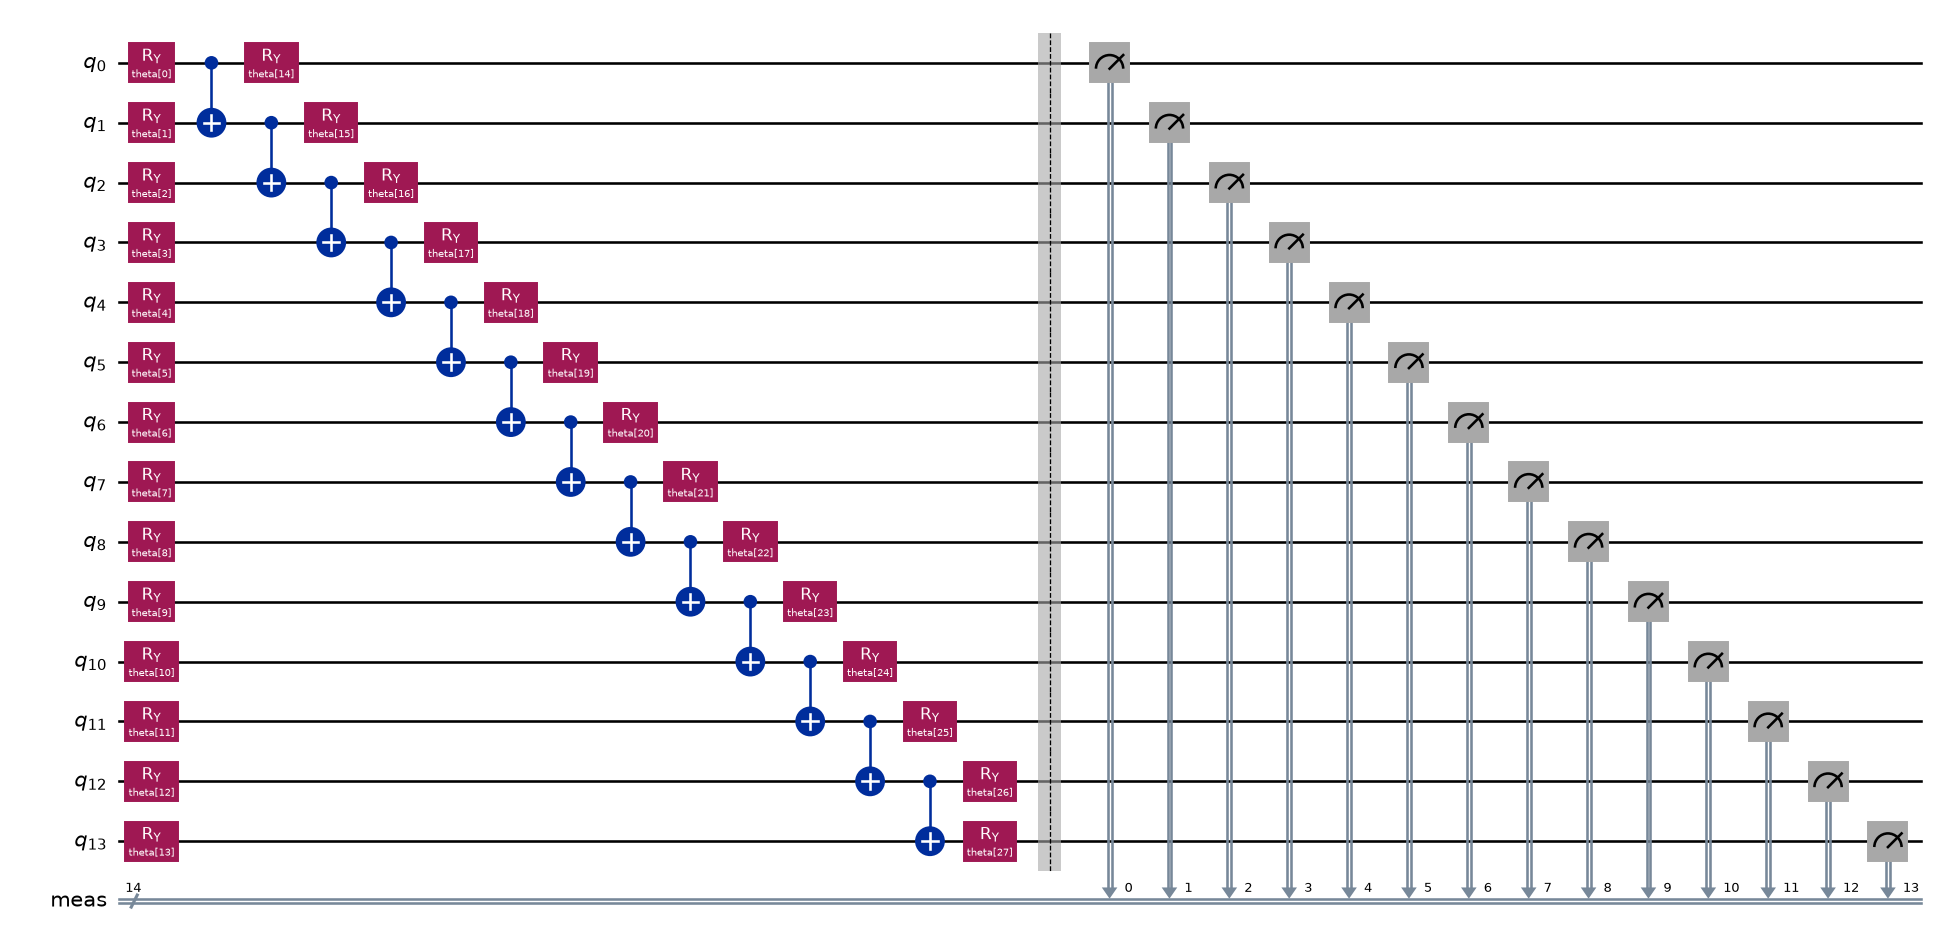

,Update k,SPSA gain a_k,Perturbation c_k
0,1,0.472184,0.150000
1,20,0.258109,0.110838
2,105,0.114945,0.093746
3,200,0.079993,0.087839


In [9]:
sampler = QuantumSampler(encoder.num_qubits, cfg["circuit"]["depth"], cfg["seed"])
theta0 = np.zeros(len(sampler.parameters))
theta0[-encoder.num_qubits:] = np.pi / 2
assert len(theta0) == 28
np.testing.assert_allclose(sampler.probabilities(theta0), 1 / 2**encoder.num_qubits, atol=1e-12)
measured_circuit = sampler.circuit.copy()
measured_circuit.measure_all()
circuit_figure = measured_circuit.draw(output="mpl", fold=-1, scale=0.62)
circuit_figure.savefig(runtime_dir / "circuit.png", dpi=160, bbox_inches="tight")
show_figure(circuit_figure)
plt.close(circuit_figure)
display(pd.DataFrame([
    {"Update k": k, "SPSA gain a_k": cfg["optimizer"]["learning_rate"] / (cfg["optimizer"]["stability_constant"] + k)**cfg["optimizer"]["alpha"],
     "Perturbation c_k": cfg["optimizer"]["perturbation"] / k**cfg["optimizer"]["gamma"]}
    for k in [1, 20, 105, 200]
]))

## 7. Short executable demonstration

This is an **execution demonstration, not the main experiment**. It calls the production `vqa.optimizer.optimize` function with the real COMET evaluator, the same 6,048-composition space, and a fresh in-memory score cache. It reuses the already-loaded model.

The demo uses **3 updates, 32 shots, one SPSA direction, no early stopping, and no final parameter averaging**. Its 11 objective calls include initial and final measurements and are deliberately small; no convergence or method-comparison claim is based on this run. Main results remain the archived 128-shot, up-to-200-update experiments.

In [10]:
demo_cfg = deepcopy(cfg)
demo_cfg["circuit"]["shots"] = 32
demo_cfg["optimizer"].update(iterations=3, resamplings=1, last_avg=1)
demo_cfg["optimizer"]["early_stopping"]["enabled"] = False
demo_dir = runtime_dir / "short_vqa"
demo_dir.mkdir()
demo_cfg["output"] = {"directory": str(demo_dir), "cache": ":memory:"}
write_json(demo_dir / "config.json", demo_cfg)
write_json(demo_dir / "encoding.json", encoder.metadata())
display(pd.DataFrame([
    {"Run": label, "Shots": c["circuit"]["shots"], "Max updates": c["optimizer"]["iterations"],
     "SPSA directions": c["optimizer"]["resamplings"], "Early stopping": c["optimizer"]["early_stopping"]["enabled"],
     "Parameter averaging": c["optimizer"]["last_avg"]}
    for label, c in [("Main experiment", cfg), ("Short demo", demo_cfg)]
]))

demo_cache = ScoreCache(":memory:", oracle.fingerprint)
demo_evaluator = Evaluator(oracle, demo_cache, oracle.catalog, demo_dir / "candidates.jsonl")
comet_before = oracle.evaluation_seconds
demo_start = time.perf_counter()
try:
    demo_result = optimize(demo_cfg, encoder, demo_evaluator, demo_dir)
    demo_summary = {"status": "completed", "command": "notebook_demo", "purpose": "execution check only",
                    **demo_result, "best": demo_evaluator.best, "counts": demo_evaluator.stats(),
                    "search_seconds": time.perf_counter()-demo_start,
                    "search_comet_seconds": oracle.evaluation_seconds-comet_before,
                    "model_fingerprint": oracle.fingerprint}
    write_json(demo_dir / "summary.json", demo_summary)
finally:
    demo_cache.close()
assert demo_result["objective_calls"] == 11
assert demo_summary["counts"]["sampled_shots"] == 352
display(pd.read_csv(demo_dir / "history.csv")[["iteration", "mean_comet_score", "best_so_far_score", "unique_sampled_compositions"]])
display(pd.DataFrame([{"Demo search seconds (model already loaded)": demo_summary["search_seconds"],
                       "COMET seconds": demo_summary["search_comet_seconds"],
                       "New COMET evaluations": demo_summary["counts"]["unique_comet_evaluations"]}]))

,Run,Shots,Max updates,SPSA directions,Early stopping,Parameter averaging
0,Main experiment,128,200,2,True,5
1,Short demo,32,3,1,False,1


iteration=  0 mean=-2.253046 best=6.857320 unique=32


iteration=  1 mean=-1.876289 best=7.438623 unique=127


iteration=  2 mean=-2.845518 best=7.438623 unique=219


iteration=  3 mean=-1.887143 best=7.543312 unique=311


,iteration,mean_comet_score,best_so_far_score,unique_sampled_compositions
0,0,-2.253046,6.857320,32
1,1,-1.876289,7.438623,127
2,2,-2.845518,7.438623,219
3,3,-1.887143,7.543312,311


,Demo search seconds (model already loaded),COMET seconds,New COMET evaluations
0,12.25762,9.703003,340


## 8. Implementation checks and exact circuit probabilities

Validation uses the **current search space**:

1. Decode all 16,384 bitstrings and check identities, grid membership, and exact fraction sums.
2. Recompute every archived shot-weighted objective from the saved measurements and real COMET scores.
3. Check random sampling order and matched distinct-composition budgets.
4. Compute exact initial/final statevector probability mass for the **best discovered composition**, including all its aliases.

The last calculation needs no new COMET predictions. It is **not** the probability of a proven global optimum. A full-space exact COMET expectation would require scores for every composition; no exhaustive COMET optimum or exact full-space mean is claimed here.

In [11]:
ratio_set = set(encoder.ratios)
composition_keys = []
for value in range(2**encoder.num_qubits):
    composition = encoder.decode(format(value, f"0{encoder.num_qubits}b"))
    assert sum(composition.ticks) == encoder.denominator
    assert composition.ticks in ratio_set
    assert all(mid in options for mid, options in zip(composition.lipid_ids, encoder.candidates))
    composition_keys.append(composition.key)
aliases = Counter(composition_keys)
assert len(aliases) == encoder.cardinality

checks = []
probability_rows = []
for run in runs:
    scores = {r["composition_key"]: r["comet_score"] for r in run["candidates"]}
    assert len(scores) == len(run["candidates"]) == run["summary"]["counts"]["unique_sampled_compositions"]
    errors = []
    for evaluation in run["evaluations"]:
        counts = evaluation["counts"]
        assert sum(counts.values()) == run["config"]["circuit"]["shots"]
        recomputed = sum(n * scores[composition_keys[int(bits, 2)]] for bits, n in counts.items()) / sum(counts.values())
        errors.append(abs(recomputed-evaluation["mean_comet_score"]))
    assert max(errors) < 1e-10
    r = run["config"]["optimizer"]["resamplings"]
    assert len(run["evaluations"]) == (2*r+1)*run["summary"]["iterations"]+2
    assert max(scores.values()) == run["summary"]["best"]["comet_score"]
    if run["random"]:
        random = run["random"]
        count = len(run["candidates"])
        indices = np.random.default_rng(random["summary"]["seed"]).choice(encoder.cardinality, count, replace=False)
        assert [c["composition_key"] for c in random["candidates"]] == [encoder.composition_at(i).key for i in indices]
    checks.append({"Seed": run["seed"], "Objective calls checked": len(errors),
                   "Maximum mean reconstruction error": max(errors), "Matched random budget": bool(run["random"])})
    target = run["summary"]["best"]["composition_key"]
    mask = np.array([key == target for key in composition_keys])
    circuit = QuantumSampler(encoder.num_qubits, run["config"]["circuit"]["depth"], run["seed"])
    p0, p1 = [float(circuit.probabilities(np.asarray(run[key]))[mask].sum())
              for key in ("initial_parameters", "final_parameters")]
    probability_rows.append({"Seed": run["seed"], "Target aliases": int(mask.sum()),
                             "Initial probability (%)": 100*p0, "Final probability (%)": 100*p1})
print(f"Validated {len(composition_keys):,} bitstrings → {len(aliases):,} unique compositions.")
print("Aliases per composition:", dict(sorted(Counter(aliases.values()).items())))
display(pd.DataFrame(checks))
display(pd.DataFrame(probability_rows))

Validated 16,384 bitstrings → 6,048 unique compositions.
Aliases per composition: {1: 768, 2: 3200, 4: 1856, 8: 224}


,Seed,Objective calls checked,Maximum mean reconstruction error,Matched random budget
0,21,527,0.0,True


,Seed,Target aliases,Initial probability (%),Final probability (%)
0,21,4,0.024414,0.427979


## 9. Main experiments and matched random search

The following results come exclusively from the bundled, verified archives. The short demo is excluded. Each random run uses the number of **distinct compositions encountered by its reference VQA**, including cached candidates and SPSA perturbations.

The mean-score curve evaluates learning; the best-so-far curve evaluates discovery. Stopping lengths are retained, and missing seeds are not imputed. Runtime is descriptive because archived VQA and random runs used different score-cache conditions and separate model processes.

In [12]:
result_rows = []
for run in runs:
    summary = run["summary"]
    result_rows.append({"VQA seed": run["seed"], "Updates": summary["iterations"],
                       "Stop reason": summary["termination_reason"],
                       "Initial sampled mean": summary["initial_mean_comet_score"],
                       "Final sampled mean": summary["final_mean_comet_score"],
                       "Best score": summary["best"]["comet_score"],
                       "Distinct compositions": summary["counts"]["unique_sampled_compositions"]})
display(pd.DataFrame(evidence["availability"]))
display(pd.DataFrame(result_rows))
print(f"Completed VQA runs: {len(runs)}; completed matched pairs: {sum(r['random'] is not None for r in runs)}.")
print("Missing seeds are not included in any aggregate.")

,seed,vqa,random
0,21,completed,completed
1,22,not available,not available
2,23,not available,not available


,VQA seed,Updates,Stop reason,Initial sampled mean,Final sampled mean,Best score,Distinct compositions
0,21,105,plateau,-3.060046,5.158117,8.464256,4682


Completed VQA runs: 1; completed matched pairs: 1.
Missing seeds are not included in any aggregate.


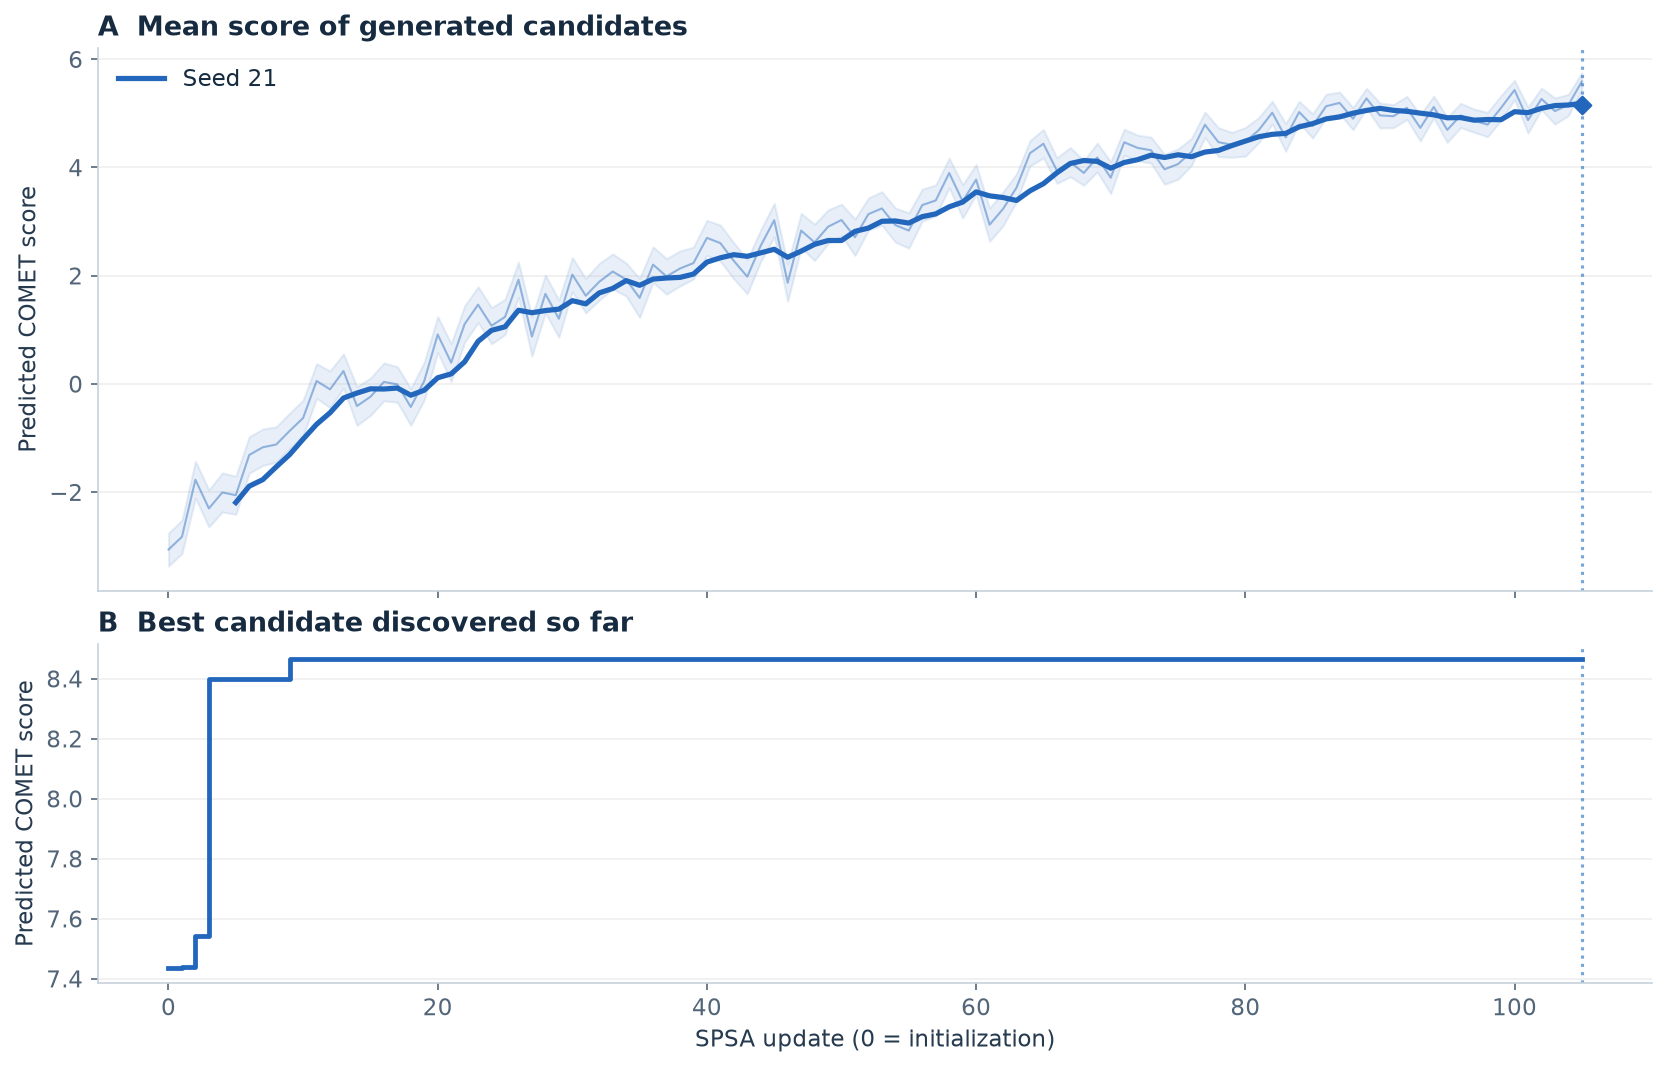

Thin lines: sampled means. Thick lines: trailing five-update means. Shading: ±1 sampling standard error. Diamonds: fresh measurement of returned parameters. Dotted lines: plateau stop.

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1.6, 1]}, layout="constrained")
colors = ["#2367BD", "#DE7B24", "#159782"]
for i, run in enumerate(runs):
    history = pd.DataFrame(run["history"])
    x = history["iteration"].astype(int).to_numpy()
    mean = history["mean_comet_score"].astype(float).to_numpy()
    sem = history["shot_standard_error"].astype(float).to_numpy()
    best = history["best_so_far_score"].astype(float).to_numpy()
    color = colors[i % len(colors)]
    axes[0].plot(x, mean, color=color, alpha=0.45, lw=1)
    axes[0].fill_between(x, mean-sem, mean+sem, color=color, alpha=0.1)
    axes[0].plot(x, trailing_mean(mean, 5), color=color, lw=2.5, label=f"Seed {run['seed']}")
    axes[0].scatter([x[-1]], [run["summary"]["final_mean_comet_score"]], marker="D", color=color, zorder=5)
    axes[1].step(x, best, where="post", color=color, lw=2.3)
    if run["summary"]["termination_reason"] == "plateau":
        for ax in axes:
            ax.axvline(x[-1], color=color, ls=":", alpha=0.6)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_ylabel("Predicted COMET score")
axes[0].set_title("A  Mean score of generated candidates", loc="left")
axes[1].set_title("B  Best candidate discovered so far", loc="left")
axes[1].set_xlabel("SPSA update (0 = initialization)")
axes[0].legend(frameon=False)
save_figure(fig, runtime_dir / "figures", "main_learning")
show_figure(fig)
plt.close(fig)
display(Markdown("Thin lines: sampled means. Thick lines: trailing five-update means. Shading: ±1 sampling standard error. Diamonds: fresh measurement of returned parameters. Dotted lines: plateau stop."))

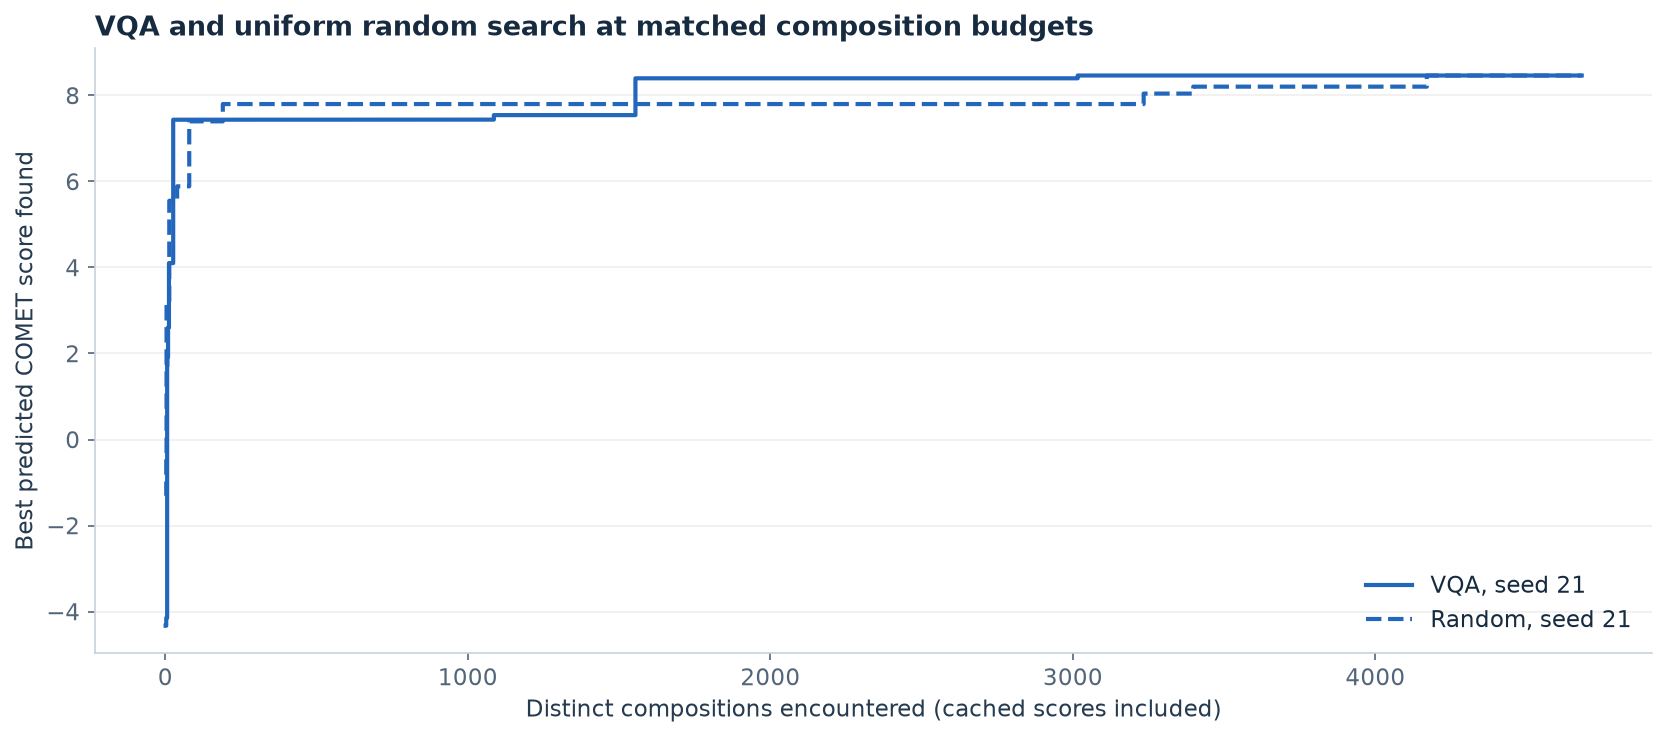

,Method,Seed,Distinct compositions,Best score,New COMET evaluations,Persistent cache hits,Total seconds (descriptive)
0,VQA,21,4682,8.464256,4558,124,306.459191
1,Random,21,4682,8.464256,4682,0,142.884560


Method                                  Random       VQA
Reference seed Distinct compositions                    
21             500                    7.800376  7.438623
               1000                   7.800376  7.438623
               2000                   7.800376  8.399100
               4682                   8.464256  8.464256

Within-batch candidate order is log order. These are not fresh-inference-count or controlled-runtime curves.


In [14]:
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
comparison_rows, prefix_rows = [], []
for i, run in enumerate(runs):
    pair = run["random"]
    if pair is None:
        continue
    for method, item, color, style in [("VQA", run, colors[i % len(colors)], "-"),
                                       ("Random", pair, colors[i % len(colors)], "--")]:
        records, summary = item["candidates"], item["summary"]
        running_best = np.maximum.accumulate([r["comet_score"] for r in records])
        method_seed = run["seed"] if method == "VQA" else summary["seed"]
        ax.step(np.arange(1, len(records)+1), running_best, where="post", color=color,
                ls=style, lw=2, label=f"{method}, seed {method_seed}")
        comparison_rows.append({"Method": method, "Seed": method_seed, "Distinct compositions": len(records),
            "Best score": float(running_best[-1]), "New COMET evaluations": summary["counts"]["unique_comet_evaluations"],
            "Persistent cache hits": summary["counts"].get("unique_loaded_from_persistent_cache", 0),
            "Total seconds (descriptive)": summary["timing"]["total_seconds"]})
        for budget in sorted({b for b in [500, 1000, 2000, len(records)] if b <= len(records)}):
            prefix_rows.append({"Reference seed": run["seed"], "Method": method,
                                "Distinct compositions": budget, "Best score": float(running_best[budget-1])})
ax.set_xlabel("Distinct compositions encountered (cached scores included)")
ax.set_ylabel("Best predicted COMET score found")
ax.set_title("VQA and uniform random search at matched composition budgets", loc="left")
ax.grid(axis="y", alpha=0.2)
if comparison_rows:
    ax.legend(frameon=False)
    save_figure(fig, runtime_dir / "figures", "random_comparison")
    show_figure(fig)
    display(pd.DataFrame(comparison_rows))
    display(pd.DataFrame(prefix_rows).pivot(index=["Reference seed", "Distinct compositions"], columns="Method", values="Best score"))
else:
    print("No completed random comparison is available.")
plt.close(fig)
print("Within-batch candidate order is log order. These are not fresh-inference-count or controlled-runtime curves.")

## 10. Final candidate and scope of ratio optimization

This submission reports **discrete VQA and discrete random search only**. No continuous-ratio refinement was performed for these reported runs. The table below identifies the best discovered formulation; it is not labeled a proven global optimum.

In [15]:
all_candidates = [("VQA", run["seed"], run["summary"]["best"]) for run in runs]
all_candidates += [("Random", run["random"]["summary"]["seed"], run["random"]["summary"]["best"])
                   for run in runs if run["random"]]
method, seed, selected = max(all_candidates, key=lambda row: row[2]["comet_score"])
final_table = pd.DataFrame(selected["components"])[["group", "mol_id", "name", "molar_fraction"]]
final_table["mol_percent"] = 100 * final_table["molar_fraction"]
display(final_table)
assert math.isclose(final_table["molar_fraction"].sum(), 1.0, abs_tol=1e-12)
found_by = [f"{method} seed {seed}" for method, seed, best in all_candidates
            if best["composition_key"] == selected["composition_key"]]
print(f"Best discovered COMET score: {selected['comet_score']:.6f}")
print("Found by:", ", ".join(found_by))
print("Cell:", cfg["condition"]["cell"], "| N/P:", cfg["condition"]["np_ratio"],
      "| Aqueous:organic:", cfg["condition"]["volumetric_ratio"])

,group,mol_id,name,molar_fraction,mol_percent
0,ionizable,6,SM-102,0.30,30.0
1,phospholipid,1,DOPE,0.15,15.0
2,sterol,2,Cholesterol,0.54,54.0
3,peg,11,C18-PEG (COMET representation),0.01,1.0


Best discovered COMET score: 8.464256
Found by: VQA seed 21, Random seed 21
Cell: DC2.4 | N/P: 5.287338420806728 | Aqueous:organic: 1:1


## 11. Interpretation, limitations, and next steps

The statements below are generated from the actual archives rather than assumed from the planned seed list.

In [16]:
statements = []
for run in runs:
    summary = run["summary"]
    initial, final = summary["initial_mean_comet_score"], summary["final_mean_comet_score"]
    coverage = summary["counts"]["unique_sampled_compositions"] / encoder.cardinality
    statements.append(f"- **Seed {run['seed']}:** sampled mean {initial:.3f} → {final:.3f}; "
                      f"{summary['iterations']} updates; termination `{summary['termination_reason']}`; "
                      f"{coverage:.1%} of distinct compositions encountered.")
    if run["random"]:
        vqa_best = summary["best"]["comet_score"]
        random_best = run["random"]["summary"]["best"]["comet_score"]
        relation = "tied within 1e-5" if abs(vqa_best-random_best) <= 1e-5 else "differed"
        statements.append(f"- The matched final best scores **{relation}**: VQA {vqa_best:.6f}, random {random_best:.6f}.")
statements.append(f"- Available evidence contains **{len(runs)} completed VQA run(s)** and "
                  f"**{sum(r['random'] is not None for r in runs)} completed matched pair(s)**.")
display(Markdown("\n".join(statements)))

- **Seed 21:** sampled mean -3.060 → 5.158; 105 updates; termination `plateau`; 77.4% of distinct compositions encountered.
- The matched final best scores **tied within 1e-5**: VQA 8.464256, random 8.464256.
- Available evidence contains **1 completed VQA run(s)** and **1 completed matched pair(s)**.

**Interpretation and limits**

- Improvement in the sampled mean supports learning of the circuit's generation distribution. Candidate discovery and mean-score improvement are distinct outcomes.
- A single seed pair and a large coverage fraction do not establish a general search-efficiency advantage. Performance may depend on the evaluation budget.
- Finite-shot means are estimates. The exact probability calculation concerns the best **discovered** formulation, not a proven optimum.
- Cache differences prevent a controlled runtime comparison. Local simulation does not establish a quantum hardware advantage.
- COMET is a fixed predictive ranking model. One cell, fold, and conformer setting do not establish biological efficacy or generalization to other conditions.

**Future work**

- Compare at least five seeds at predefined budgets of 500, 1,000, and 2,000 distinct formulations.
- Use independent evaluation shots to measure the mean and probability of exceeding a predefined score threshold.
- Test circuit depth, entanglement, and encoding choices under equal evaluation budgets.
- Standardize cache and model-loading conditions for runtime comparisons.
- Check robustness across supported cells and conformer settings, followed by experimental validation.

**Reproduction**

Submit this `.ipynb` alone. To inspect the results, open the saved notebook without running it. To reproduce the executable example, use a Python 3.12 kernel and **Run All** from any writable directory. Initial setup needs Git, internet access, and space for the external COMET checkpoint and dependencies. The generated `lipoq_workspace` directory contains the embedded source, configuration, evidence, downloaded assets, and new demo outputs. Existing archived main results are analyzed from the embedded evidence.

The source payload retains the common, VQA, and random-search modules in readable text. The evidence payload is a compressed copy of actual run records with source-file hashes. Both are verified before use. The original COMET adapter bytes are preserved, keeping the model fingerprint comparable to the archived experiment.

To run additional main experiments, the generated `configs/vqa.yaml` and `vqa`/`random_search` modules expose the same configuration and command interfaces as the repository. These longer experiments are deliberately separate from Run All. Changing the search space or experimental protocol requires fresh compatible evidence; it does not change the saved results retroactively.

**References and attribution**

- [COMET source and pretrained assets](https://github.com/alvinchangw/COMET)
- [Designing lipid nanoparticles using a transformer-based neural network](https://www.nature.com/articles/s41565-025-01975-4)
- [Variational quantum algorithm for unconstrained black box binary optimization](https://quantum-journal.org/papers/q-2023-01-26-909/)
- [Qiskit SPSA documentation](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.optimizers.SPSA.html)

LipoQ implements circuit-distribution search inspired by black-box variational optimization. It does not reproduce the reference paper's complete QITE/VarQFS algorithm.